# EDA: Inside Airbnb listings, cities A and B
Group assignment 2, deliverable 3.1. Region **California**; **A = Los Angeles**, **B = San Francisco**. City C (Santa Clara County) is not loaded anywhere in this notebook: it stays unseen until the pipeline and model for A and B are finished.

**How to read it.** Every output is preceded by a one-line caption saying what one row is and what the columns mean. Spark does the heavy aggregation; the ~50k typed rows are pulled into pandas only for plots and correlations (as in Lab 6).
**How to run.** Databricks serverless, *Run all*. The notebook copies `data/listings_<City>.csv.gz` from the repo into a Unity Catalog volume, loads it into Delta tables in `workspace.airbnb_eda` and works from there (about 5 min).

## Summary
**What we know**
1. **Data.** LA: 43,781 listings scraped 2026-09-14 to 2026-09-16 (75 % on the 15th). SF: 7,405 listings scraped 2026-09-14. 90 columns. One row is one listing; `id` is unique within and across the cities.
2. **Schema holes.** 13 (LA) and 14 (SF) columns are 100 % empty. `neighbourhood_group_cleansed` is filled in LA and empty in SF, so the cities do not share the same usable columns.
3. **`price` is a quote for one future stay**, not a plain nightly price. The quoted stay is the host's minimum stay: listings with `minimum_nights >= 28` (48 % of LA, 39 % of SF) are monthly stays priced at about **60 %** of comparable short stays.
4. **16 % (LA) and 23 % (SF) of listings have no price.** Mostly stale rows (`source = "previous scrape"`: 14 % of LA, 23 % of SF) with no availability. Review columns are missing exactly when a listing has no reviews.
5. **Price is right-skewed** (mean about 1.7 times the median) and has 26 placeholder values ($5,000 to $99,999 for one or two guests, many of them hotel rooms). Outliers are classified, not deleted.
6. **Leakage.** Four columns are computed from the price: `price_quote_price_per_night`, `price_quote_total_price`, `price_quote_raw`, `estimated_revenue_l365d`. Quote dates describe how the target was measured. Availability and review columns are outcomes of past demand.
7. **A and B differ.** SF has smaller units, prices 24 to 90 % higher than LA at equal size, more stale rows; the cities share one neighbourhood name but almost all property types.

**What we do not know yet:** how stable the price is over time (one snapshot, quotes for different dates; in SF the short-stay median moves from $276 to $937 across lead-time groups, in LA only from $235 to $300); whether the placeholder rule is exactly right; how a model behaves on unpriced and stale listings; whether free text helps; how any of this transfers to another city (untested by design).

## 1. Setup and loading

In [0]:
import datetime
import os
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyspark.sql import functions as F, Window

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

CATALOG, SCHEMA, VOLUME = "workspace", "airbnb_eda", "raw"
CITIES = ["Los_Angeles", "San_Francisco"]            # city C is intentionally not listed
SHORT = {"Los_Angeles": "LA", "San_Francisco": "SF"}
COLORS = {"Los_Angeles": "#1f77b4", "San_Francisco": "#ff7f0e"}
EXPECTED_ROWS = {"Los_Angeles": 43781, "San_Francisco": 7405}   # rows in the CSV files, used by the CHECK below

Copy the two archives from the repo's `data/` folder into a volume (Spark cannot read workspace files directly on serverless). If the copy fails, upload the files to the volume by hand.

In [0]:
spark.sql(f"CREATE SCHEMA IF NOT EXISTS {CATALOG}.{SCHEMA}")
spark.sql(f"CREATE VOLUME IF NOT EXISTS {CATALOG}.{SCHEMA}.{VOLUME}")
VOL = f"/Volumes/{CATALOG}/{SCHEMA}/{VOLUME}"

notebook_path = dbutils.notebook.entry_point.getDbutils().notebook().getContext().notebookPath().get()
REPO_DATA = os.path.normpath(os.path.join("/Workspace" + os.path.dirname(notebook_path), "..", "data"))

for city in CITIES:
    name = f"listings_{city}.csv.gz"
    target = f"{VOL}/{name}"
    if not os.path.exists(target):
        source = os.path.join(REPO_DATA, name)
        if not os.path.exists(source):
            raise FileNotFoundError(f"{source} not found. Upload {name} to {VOL} by hand (Catalog > {CATALOG} > {SCHEMA} > {VOLUME} > Upload).")
        shutil.copyfile(source, target)
    print(f"{name}: {os.path.getsize(target) / 1e6:,.1f} MB in {VOL}")

listings_Los_Angeles.csv.gz: 26.8 MB in /Volumes/workspace/airbnb_eda/raw
listings_San_Francisco.csv.gz: 3.4 MB in /Volumes/workspace/airbnb_eda/raw


Read both files as text (`multiLine` and `escape` matter: descriptions contain line breaks and quotes) and save them as the Delta table `listings_raw`. Typing happens later, on purpose.

In [0]:
def read_city(city):
    return (spark.read.option("header", True).option("multiLine", True)
            .option("quote", '"').option("escape", '"')
            .csv(f"{VOL}/listings_{city}.csv.gz")
            .withColumn("city", F.lit(city)))

(read_city(CITIES[0]).unionByName(read_city(CITIES[1]))
    .write.mode("overwrite").option("overwriteSchema", "true")
    .saveAsTable(f"{CATALOG}.{SCHEMA}.listings_raw"))
listings_raw = spark.table(f"{CATALOG}.{SCHEMA}.listings_raw")

In [0]:
# CHECK
n_rows = {r["city"]: r["n"] for r in listings_raw.groupBy("city").agg(F.count("*").alias("n")).collect()}
n_ids = {r["city"]: r["n"] for r in listings_raw.groupBy("city").agg(F.countDistinct("id").alias("n")).collect()}
for city in CITIES:
    assert n_rows[city] == EXPECTED_ROWS[city], f"{city}: expected {EXPECTED_ROWS[city]:,} rows, got {n_rows[city]:,}. Did the CSV read split multi-line rows?"
    assert n_ids[city] == n_rows[city], f"{city}: id should be unique"
print("listings_raw loaded correctly:", n_rows)

listings_raw loaded correctly: {'Los_Angeles': 43781, 'San_Francisco': 7405}


## 2. Understand the problem first
**Question:** *what price should we suggest for a listing?* The user is a host (or the platform on the host's behalf) setting a nightly price for a listing in a city; the decision it changes is the number typed into Airbnb. The model must work for the two cities we train on and then for a third, unseen, city.

**Grain:** one row = one Airbnb listing as it looked on the snapshot date. The snapshot is a single scrape per city, so this is a cross-section, not a time series: `price` is what a price quote returned on that day, review counts are cumulative to that day, and listings removed before the scrape are absent.

## 3. Dataset description

**Snapshot dates.** One row per (city, `last_scraped` date): how many listings carry that date.

In [0]:
display(listings_raw.groupBy("city", "last_scraped").agg(F.count("*").alias("listings")).orderBy("city", "last_scraped"))

city,last_scraped,listings
Los_Angeles,2026-09-14,10985
Los_Angeles,2026-09-15,32794
Los_Angeles,2026-09-16,2
San_Francisco,2026-09-14,7405


**Scrape runs.** One row per city: number of distinct `scrape_id`s (one means one scrape run) and the first and last `last_scraped` date.

In [0]:
display(listings_raw.groupBy("city").agg(
    F.countDistinct("scrape_id").alias("distinct_scrape_ids"),
    F.min("last_scraped").alias("first_last_scraped"),
    F.max("last_scraped").alias("latest_last_scraped")).orderBy("city"))

city,distinct_scrape_ids,first_last_scraped,latest_last_scraped
Los_Angeles,1,2026-09-14,2026-09-16
San_Francisco,1,2026-09-14,2026-09-14


**Record counts.** One row per city: rows, distinct listing ids, distinct hosts, listings per host, columns in the file (without our own `city` column).

In [0]:
display(listings_raw.groupBy("city").agg(
    F.count("*").alias("rows"),
    F.countDistinct("id").alias("distinct_ids"),
    F.countDistinct("host_id").alias("distinct_hosts"))
    .withColumn("duplicate_ids", F.col("rows") - F.col("distinct_ids"))
    .withColumn("listings_per_host", F.round(F.col("rows") / F.col("distinct_hosts"), 2))
    .withColumn("columns_in_file", F.lit(len(listings_raw.columns) - 1))
    .orderBy("city"))

ids = {c: set(r["id"] for r in listings_raw.filter(F.col("city") == c).select("id").collect()) for c in CITIES}
print("Listing ids that appear in both cities:", len(ids[CITIES[0]] & ids[CITIES[1]]))

city,rows,distinct_ids,distinct_hosts,duplicate_ids,listings_per_host,columns_in_file
Los_Angeles,43781,43781,20912,0,2.09,90
San_Francisco,7405,7405,3489,0,2.12,90


Listing ids that appear in both cities: 0


**First look.** Ten rows of a few columns, exactly as loaded (all text).

In [0]:
display(listings_raw.select("city", "id", "name", "room_type", "property_type", "accommodates", "bedrooms", "price",
                            "minimum_nights", "availability_365", "number_of_reviews", "source").limit(10))

city,id,name,room_type,property_type,accommodates,bedrooms,price,minimum_nights,availability_365,number_of_reviews,source
San_Francisco,41789520,Private room with private bathroom in Castro condo,Private room,Private room in condo,2,1,$195.50,2,329,154,null
San_Francisco,49838960,Twin Peaks Oasis,Entire home/apt,Entire home,6,3,$308.41,30,174,25,null
San_Francisco,1039800918426600713,"Mobility accessible, & The Line signature styling",Private room,Room in hotel,2,1,null,1,0,1,previous scrape
San_Francisco,1039801086862887937,"Table for dining/working, coffeemaker & fast WiFi",Private room,Room in hotel,2,1,null,1,0,1,previous scrape
San_Francisco,1039801616708689955,"Skyline views, grind coffee machine & local art",Private room,Room in hotel,2,1,null,1,0,1,previous scrape
San_Francisco,1039801771130375737,"Deep soaking tub, robes & enviable city views",Private room,Room in hotel,2,1,null,1,0,1,previous scrape
San_Francisco,1039801777689850626,Understated chic styling & fully stocked minibar,Private room,Room in hotel,2,1,null,1,0,8,previous scrape
San_Francisco,783821,"Exquisite Castro Jewel box, Laundry, Parking",Entire home/apt,Entire rental unit,2,1,$196.01,30,204,38,null
San_Francisco,23353721,"2 bedroom + Den, 2 bath, Parking, In Unit Laundry.",Entire home/apt,Entire rental unit,5,2,$266.50,30,250,31,null
San_Francisco,49418236,"Prime Mid Century Flat, Laundry, Parking.",Entire home/apt,Entire rental unit,4,2,$231.73,30,231,25,null


**Raw profile, one table per city.** One row per column: `null_pct` = share of empty values, `distinct_approx` = approximate number of distinct values (error about 5 %), `min_as_text` / `max_as_text` = smallest and largest value **compared as text** (so `"$1,000"` sorts before `"$95"`). Sorted with the emptiest columns first.

In [0]:
def profile(df):
    return (df.agg(*[F.struct(
                F.lit(c).alias("column"),
                F.round(F.avg(F.col(c).isNull().cast("int")) * 100, 2).alias("null_pct"),
                F.approx_count_distinct(c).alias("distinct_approx"),
                F.substring(F.min(c), 1, 40).alias("min_as_text"),
                F.substring(F.max(c), 1, 40).alias("max_as_text")).alias(c) for c in df.columns])
            .select(F.explode(F.array(*df.columns)).alias("p")).select("p.*"))

print("LOS ANGELES (A)")
display(profile(listings_raw.filter(F.col("city") == "Los_Angeles").drop("city")).orderBy(F.desc("null_pct"), "column"))

LOS ANGELES (A)


column,null_pct,distinct_approx,min_as_text,max_as_text
bathrooms,100.0,0,null,null
calendar_updated,100.0,0,null,null
host_acceptance_rate,100.0,0,null,null
host_neighbourhood,100.0,0,null,null
host_response_rate,100.0,0,null,null
host_response_time,100.0,0,null,null
host_since,100.0,0,null,null
host_thumbnail_url,100.0,0,null,null
host_total_listings_count,100.0,0,null,null
instant_bookable,100.0,0,null,null


In [0]:
print("SAN FRANCISCO (B)")
display(profile(listings_raw.filter(F.col("city") == "San_Francisco").drop("city")).orderBy(F.desc("null_pct"), "column"))

SAN FRANCISCO (B)


column,null_pct,distinct_approx,min_as_text,max_as_text
bathrooms,100.0,0,null,null
calendar_updated,100.0,0,null,null
host_acceptance_rate,100.0,0,null,null
host_neighbourhood,100.0,0,null,null
host_response_rate,100.0,0,null,null
host_response_time,100.0,0,null,null
host_since,100.0,0,null,null
host_thumbnail_url,100.0,0,null,null
host_total_listings_count,100.0,0,null,null
instant_bookable,100.0,0,null,null


**Column groups.** One row per group of columns in the file and how many columns it holds.

In [0]:
COLUMN_GROUPS = {
    "identifiers / scrape metadata": ["id", "listing_url", "scrape_id", "last_scraped", "source", "calendar_last_scraped", "picture_url"],
    "free text": ["name", "description", "neighborhood_overview", "host_about"],
    "host": ["host_id", "host_url", "host_profile_id", "host_profile_url", "host_name", "host_since", "hosts_time_as_user_years",
             "hosts_time_as_user_months", "hosts_time_as_host_years", "hosts_time_as_host_months", "host_location",
             "host_response_time", "host_response_rate", "host_acceptance_rate", "host_is_superhost", "host_thumbnail_url",
             "host_picture_url", "host_neighbourhood", "host_listings_count", "host_total_listings_count", "host_verifications",
             "host_has_profile_pic", "host_identity_verified", "calculated_host_listings_count",
             "calculated_host_listings_count_entire_homes", "calculated_host_listings_count_private_rooms",
             "calculated_host_listings_count_shared_rooms"],
    "location": ["neighbourhood", "neighbourhood_cleansed", "neighbourhood_group_cleansed", "latitude", "longitude"],
    "property": ["property_type", "room_type", "accommodates", "bathrooms", "bathrooms_text", "bedrooms", "beds", "amenities"],
    "price and price quote": ["price", "price_quote_checkin_date", "price_quote_checkout_date", "price_quote_total_price",
                              "price_quote_price_per_night", "price_quote_raw", "estimated_revenue_l365d"],
    "booking rules": ["minimum_nights", "maximum_nights", "minimum_minimum_nights", "maximum_minimum_nights", "minimum_maximum_nights",
                      "maximum_maximum_nights", "minimum_nights_avg_ntm", "maximum_nights_avg_ntm", "calendar_updated", "instant_bookable", "license"],
    "availability and demand": ["has_availability", "availability_30", "availability_60", "availability_90", "availability_365",
                                "availability_eoy", "estimated_occupancy_l365d"],
    "reviews": ["number_of_reviews", "number_of_reviews_ltm", "number_of_reviews_l30d", "number_of_reviews_ly", "first_review", "last_review",
                "reviews_per_month", "review_scores_rating", "review_scores_accuracy", "review_scores_cleanliness", "review_scores_checkin",
                "review_scores_communication", "review_scores_location", "review_scores_value"],
}
file_columns = [c for c in listings_raw.columns if c != "city"]
covered = {c for cols in COLUMN_GROUPS.values() for c in cols}
print("Columns in the file that are in no group:", sorted(set(file_columns) - covered))
display(pd.DataFrame({"column_group": list(COLUMN_GROUPS), "n_columns": [len(v) for v in COLUMN_GROUPS.values()],
                      "columns": [", ".join(v) for v in COLUMN_GROUPS.values()]}))

Columns in the file that are in no group: []


column_group,n_columns,columns
identifiers / scrape metadata,7,"id, listing_url, scrape_id, last_scraped, source, calendar_last_scraped, picture_url"
free text,4,"name, description, neighborhood_overview, host_about"
host,27,"host_id, host_url, host_profile_id, host_profile_url, host_name, host_since, hosts_time_as_user_years, hosts_time_as_user_months, hosts_time_as_host_years, hosts_time_as_host_months, host_location, host_response_time, host_response_rate, host_acceptance_rate, host_is_superhost, host_thumbnail_url, host_picture_url, host_neighbourhood, host_listings_count, host_total_listings_count, host_verifications, host_has_profile_pic, host_identity_verified, calculated_host_listings_count, calculated_host_listings_count_entire_homes, calculated_host_listings_count_private_rooms, calculated_host_listings_count_shared_rooms"
location,5,"neighbourhood, neighbourhood_cleansed, neighbourhood_group_cleansed, latitude, longitude"
property,8,"property_type, room_type, accommodates, bathrooms, bathrooms_text, bedrooms, beds, amenities"
price and price quote,7,"price, price_quote_checkin_date, price_quote_checkout_date, price_quote_total_price, price_quote_price_per_night, price_quote_raw, estimated_revenue_l365d"
booking rules,11,"minimum_nights, maximum_nights, minimum_minimum_nights, maximum_minimum_nights, minimum_maximum_nights, maximum_maximum_nights, minimum_nights_avg_ntm, maximum_nights_avg_ntm, calendar_updated, instant_bookable, license"
availability and demand,7,"has_availability, availability_30, availability_60, availability_90, availability_365, availability_eoy, estimated_occupancy_l365d"
reviews,14,"number_of_reviews, number_of_reviews_ltm, number_of_reviews_l30d, number_of_reviews_ly, first_review, last_review, reviews_per_month, review_scores_rating, review_scores_accuracy, review_scores_cleanliness, review_scores_checkin, review_scores_communication, review_scores_location, review_scores_value"


**Duplicates.** One row per (city, check): `surplus_rows` = rows that are repeats of another row under that definition (0 means none).

In [0]:
rows = []
for city in CITIES:
    d = listings_raw.filter(F.col("city") == city).drop("city")
    n = d.count()
    rows += [
        {"city": city, "check": "row identical to another row in all columns", "surplus_rows": n - d.dropDuplicates().count()},
        {"city": city, "check": "same listing id", "surplus_rows": n - d.select("id").distinct().count()},
        {"city": city, "check": "same name + latitude + longitude", "surplus_rows": n - d.select("name", "latitude", "longitude").distinct().count()},
        {"city": city, "check": "same host + latitude + longitude", "surplus_rows": n - d.select("host_id", "latitude", "longitude").distinct().count()},
    ]
display(pd.DataFrame(rows))

city,check,surplus_rows
Los_Angeles,row identical to another row in all columns,0
Los_Angeles,same listing id,0
Los_Angeles,same name + latitude + longitude,201
Los_Angeles,same host + latitude + longitude,2076
San_Francisco,row identical to another row in all columns,0
San_Francisco,same listing id,0
San_Francisco,same name + latitude + longitude,257
San_Francisco,same host + latitude + longitude,954


**Missing values in disguise** (raw text). One row per column that contains text such as `N/A`, `nan`, `-` or blank-only strings instead of a real null. Nothing listed means none found.

In [0]:
DISGUISE = ["", "N/A", "n/a", "NA", "NaN", "nan", "null", "None", "none", "-", "?"]
rows = []
for city in CITIES:
    d = listings_raw.filter(F.col("city") == city).drop("city")
    k = d.agg(*[F.sum(F.trim(F.col(c)).isin(DISGUISE).cast("int")).alias(c) for c in d.columns]).first().asDict()
    rows += [{"column": c, "city": city, "placeholder_text_values": int(v)} for c, v in k.items() if v]
disguised = pd.DataFrame(rows, columns=["column", "city", "placeholder_text_values"])
print("columns with placeholder text:", len(disguised))
display(disguised)

columns with placeholder text: 5


column,city,placeholder_text_values
host_about,Los_Angeles,1
host_verifications,Los_Angeles,43781
license,Los_Angeles,4
host_about,San_Francisco,3
host_verifications,San_Francisco,7405


## 4. Fix the types
Everything arrived as text. Steps: blank / placeholder text becomes a real null; numbers, dates and `t`/`f` flags get proper types (`try_cast`, so a bad value becomes null instead of an error); `price` loses `$` and `,`; and a few helper columns are derived (bathrooms from `bathrooms_text`, quote details from the JSON in `price_quote_raw`, number of amenities, stay type). Saved as the table `listings_typed`.

In [0]:
ID_COLS = ["id", "scrape_id", "host_id"]      # up to 19 digits: cast straight to bigint (a double would lose digits)
INT_COLS = ["host_listings_count", "calculated_host_listings_count",
            "calculated_host_listings_count_entire_homes", "calculated_host_listings_count_private_rooms",
            "calculated_host_listings_count_shared_rooms", "hosts_time_as_host_years", "accommodates", "minimum_nights",
            "maximum_nights", "availability_30", "availability_60", "availability_90", "availability_365", "availability_eoy",
            "number_of_reviews", "number_of_reviews_ltm", "number_of_reviews_l30d", "estimated_occupancy_l365d"]
DOUBLE_COLS = ["latitude", "longitude", "bedrooms", "beds", "price_quote_total_price", "price_quote_price_per_night",
               "estimated_revenue_l365d", "reviews_per_month", "review_scores_rating", "review_scores_accuracy",
               "review_scores_cleanliness", "review_scores_checkin", "review_scores_communication",
               "review_scores_location", "review_scores_value"]
DATE_COLS = ["last_scraped", "first_review", "last_review", "price_quote_checkin_date", "price_quote_checkout_date"]
BOOL_COLS = ["host_is_superhost", "host_identity_verified", "host_has_profile_pic", "has_availability"]
STR_COLS = ["city", "source", "name", "description", "property_type", "room_type", "neighbourhood_cleansed",
            "neighbourhood_group_cleansed", "bathrooms_text", "amenities", "license", "price_quote_raw"]

def blank_to_null(c):
    return F.when(F.trim(F.col(c)).isin(DISGUISE), F.lit(None).cast("string")).otherwise(F.col(c))

cleaned = listings_raw.select([blank_to_null(c).alias(c) for c in listings_raw.columns])   # all 90 columns, still text

typed = cleaned.select(
    *[F.expr(f"try_cast(`{c}` as bigint)").alias(c) for c in ID_COLS],
    *[F.expr(f"try_cast(try_cast(`{c}` as double) as bigint)").alias(c) for c in INT_COLS],
    *[F.expr(f"try_cast(`{c}` as double)").alias(c) for c in DOUBLE_COLS],
    *[F.expr(f"try_cast(`{c}` as date)").alias(c) for c in DATE_COLS],
    *[F.when(F.col(c) == "t", True).when(F.col(c) == "f", False).alias(c) for c in BOOL_COLS],
    *[F.col(c) for c in STR_COLS],
    F.col("price").alias("price_text"),
    F.expr("try_cast(regexp_replace(price, '[$,]', '') as double)").alias("price"),
)

bath = F.lower(F.col("bathrooms_text"))
bath_digits = F.regexp_extract("bathrooms_text", r"(\d+(?:\.\d+)?)", 1)
amenities_list = F.from_json("amenities", "array<string>")

typed = (typed
    # details of the price quote (JSON string)
    .withColumn("quote_is_available", F.get_json_object("price_quote_raw", "$.quote.is_available") == "true")
    .withColumn("quote_is_monthly", F.get_json_object("price_quote_raw", "$.quote.is_monthly_priced") == "true")
    .withColumn("quote_json_price_per_night",
                F.expr("try_cast(get_json_object(price_quote_raw, '$.quote.price_per_night') as double)"))
    .withColumn("quote_nights", F.datediff("price_quote_checkout_date", "price_quote_checkin_date"))
    .withColumn("quote_lead_days", F.datediff("price_quote_checkin_date", "last_scraped"))
    # bathrooms: the numeric column is empty, the count is inside the text ("1.5 shared baths", "Half-bath")
    .withColumn("bathrooms_num",
                F.when(F.col("bathrooms_text").isNull(), F.lit(None).cast("double"))
                 .when(bath.contains("half") & (bath_digits == ""), F.lit(0.5))
                 .when(bath_digits == "", F.lit(None).cast("double"))
                 .otherwise(bath_digits.cast("double")))
    .withColumn("bathroom_shared", F.when(bath.isNull(), F.lit(None).cast("boolean")).otherwise(bath.contains("shared")))
    .withColumn("n_amenities", F.when(amenities_list.isNull(), F.lit(None).cast("int")).otherwise(F.size(amenities_list)))
    .withColumn("has_license", F.col("license").isNotNull())
    # data-collection flag: rows Inside Airbnb carried over from an earlier scrape
    .withColumn("is_stale", F.coalesce(F.col("source") == "previous scrape", F.lit(False)))
    .withColumn("source_label", F.when(F.col("is_stale"), "previous scrape").otherwise("city scrape"))
    # long stays are priced as monthly rentals (see section 8)
    .withColumn("is_monthly_rental", F.col("minimum_nights") >= 28)
    .withColumn("stay_type", F.when(F.col("minimum_nights") >= 28, "monthly").when(F.col("minimum_nights") < 28, "short"))
    .withColumn("price_per_guest", F.col("price") / F.col("accommodates"))
    .withColumn("price_status",
                F.when(F.col("price").isNotNull(), "priced")
                 .when(F.col("price_quote_raw").isNull(), "no quote at all")
                 .when(F.col("quote_is_available") == F.lit(False), "quote says not available")
                 .otherwise("quote has only a monthly total")))

typed.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(f"{CATALOG}.{SCHEMA}.listings_typed")
typed = spark.table(f"{CATALOG}.{SCHEMA}.listings_typed")
print("typed columns:", len(typed.columns))

typed columns: 74


**Before and after.** Five rows: the price text and the number it became, the bathrooms text and its parsed value, the amenities count, the stay type.

In [0]:
display(typed.filter(F.col("price").isNotNull()).select(
    "city", "price_text", "price", "bathrooms_text", "bathrooms_num", "bathroom_shared", "n_amenities",
    "minimum_nights", "stay_type", "quote_nights", "quote_is_monthly").limit(8))

city,price_text,price,bathrooms_text,bathrooms_num,bathroom_shared,n_amenities,minimum_nights,stay_type,quote_nights,quote_is_monthly
Los_Angeles,$76.31,76.31,1 shared bath,1.0,true,77,30,monthly,30,true
Los_Angeles,$215.21,215.21,1 private bath,1.0,false,19,7,short,7,false
Los_Angeles,$99.40,99.4,1 bath,1.0,false,32,30,monthly,30,true
Los_Angeles,$69.50,69.5,1 shared bath,1.0,true,72,30,monthly,30,true
Los_Angeles,$173.25,173.25,1 bath,1.0,false,53,30,monthly,30,true
Los_Angeles,$178.25,178.25,1 bath,1.0,false,27,1,short,1,false
Los_Angeles,$80.13,80.13,1 shared bath,1.0,true,48,31,monthly,31,true
Los_Angeles,$156.34,156.34,1 bath,1.0,false,28,1,short,1,false


**Schema after typing.** One row per column of `listings_typed` with its Spark type.

In [0]:
display(pd.DataFrame(typed.dtypes, columns=["column", "spark_type"]))

column,spark_type
id,bigint
scrape_id,bigint
host_id,bigint
host_listings_count,bigint
calculated_host_listings_count,bigint
calculated_host_listings_count_entire_homes,bigint
calculated_host_listings_count_private_rooms,bigint
calculated_host_listings_count_shared_rooms,bigint
hosts_time_as_host_years,bigint
accommodates,bigint


In [0]:
# CHECK
assert dict(typed.dtypes)["price"] == "double", "price should be a double"
assert typed.filter(F.col("id").isNull()).count() == 0, "some ids failed to cast"
assert typed.select("city", "id").distinct().count() == typed.count(), "id should still be unique after the cast"
priced = {r["city"]: r["n"] for r in typed.filter(F.col("price").isNotNull()).groupBy("city").agg(F.count("*").alias("n")).collect()}
assert priced == {"Los_Angeles": 36687, "San_Francisco": 5691}, f"unexpected number of priced listings: {priced}"
print("types fixed; priced listings:", priced)

types fixed; priced listings: {'Los_Angeles': 36687, 'San_Francisco': 5691}


## 5. Missingness

**Null rate of every column** (after turning placeholder text into nulls). One row per column; `null_pct_*` = % empty, `null_n_*` = number of empty rows, `kind` says whether the column is empty in both cities, in one, partly, or complete.

In [0]:
n_city = {r["city"]: r["n"] for r in typed.groupBy("city").agg(F.count("*").alias("n")).collect()}
rows = []
for city in CITIES:
    d = cleaned.filter(F.col("city") == city).drop("city")
    k = d.agg(*[F.sum(F.col(c).isNull().cast("int")).alias(c) for c in d.columns]).first().asDict()
    for c, v in k.items():
        rows.append({"column": c, "city": SHORT[city], "null_n": int(v or 0), "null_pct": round(100 * int(v or 0) / n_city[city], 2)})
nulls = pd.DataFrame(rows).pivot(index="column", columns="city", values=["null_n", "null_pct"])
nulls.columns = [f"{a}_{b}" for a, b in nulls.columns]
nulls = nulls.reset_index()

def kind(r):
    full, part = (r.null_pct_LA == 100, r.null_pct_SF == 100), (r.null_pct_LA > 0, r.null_pct_SF > 0)
    if all(full): return "empty in both cities"
    if any(full): return "empty in one city"
    return "partly missing" if any(part) else "complete"

nulls["kind"] = nulls.apply(kind, axis=1)
nulls = nulls.sort_values(["null_pct_LA", "null_pct_SF"], ascending=False)
display(nulls[["column", "null_pct_LA", "null_pct_SF", "null_n_LA", "null_n_SF", "kind"]])

column,null_pct_LA,null_pct_SF,null_n_LA,null_n_SF,kind
bathrooms,100.0,100.0,43781.0,7405.0,empty in both cities
calendar_updated,100.0,100.0,43781.0,7405.0,empty in both cities
host_acceptance_rate,100.0,100.0,43781.0,7405.0,empty in both cities
host_neighbourhood,100.0,100.0,43781.0,7405.0,empty in both cities
host_response_rate,100.0,100.0,43781.0,7405.0,empty in both cities
host_response_time,100.0,100.0,43781.0,7405.0,empty in both cities
host_since,100.0,100.0,43781.0,7405.0,empty in both cities
host_thumbnail_url,100.0,100.0,43781.0,7405.0,empty in both cities
host_total_listings_count,100.0,100.0,43781.0,7405.0,empty in both cities
host_verifications,100.0,100.0,43781.0,7405.0,empty in both cities


**Counts by kind.** One row per kind of column and how many columns fall into it.

In [0]:
display(nulls.groupby("kind").agg(n_columns=("column", "count"), columns=("column", lambda s: ", ".join(sorted(s)) if len(s) <= 14 else "(" + str(len(s)) + " columns)")).reset_index())

kind,n_columns,columns
complete,44,(44 columns)
empty in both cities,13,"bathrooms, calendar_updated, host_acceptance_rate, host_neighbourhood, host_response_rate, host_response_time, host_since, host_thumbnail_url, host_total_listings_count, host_verifications, instant_bookable, neighborhood_overview, neighbourhood"
empty in one city,1,neighbourhood_group_cleansed
partly missing,32,(32 columns)


**Missingness pattern 1: reviews.** One row per (city, has at least one review): the share of listings with no rating / reviews per month / first review.

In [0]:
display(typed.withColumn("has_reviews", F.col("number_of_reviews") > 0)
    .groupBy("city", "has_reviews").agg(
        F.count("*").alias("listings"),
        F.round(100 * F.avg(F.col("review_scores_rating").isNull().cast("int")), 2).alias("pct_rating_missing"),
        F.round(100 * F.avg(F.col("reviews_per_month").isNull().cast("int")), 2).alias("pct_reviews_per_month_missing"),
        F.round(100 * F.avg(F.col("first_review").isNull().cast("int")), 2).alias("pct_first_review_missing"))
    .orderBy("city", "has_reviews"))

city,has_reviews,listings,pct_rating_missing,pct_reviews_per_month_missing,pct_first_review_missing
Los_Angeles,false,10845,100.0,100.0,100.0
Los_Angeles,true,32936,0.0,0.0,0.0
San_Francisco,false,1603,100.0,100.0,100.0
San_Francisco,true,5802,0.0,0.0,0.0


**Missingness pattern 2: why is the price missing?** One row per (city, price status): number and share of the city's listings.

In [0]:
display(typed.groupBy("city", "price_status").agg(F.count("*").alias("listings"))
    .withColumn("pct_of_city", F.round(100 * F.col("listings") / F.sum("listings").over(Window.partitionBy("city")), 1))
    .orderBy("city", F.desc("listings")))

city,price_status,listings,pct_of_city
Los_Angeles,priced,36687,83.8
Los_Angeles,no quote at all,5038,11.5
Los_Angeles,quote has only a monthly total,1672,3.8
Los_Angeles,quote says not available,384,0.9
San_Francisco,priced,5691,76.9
San_Francisco,no quote at all,1215,16.4
San_Francisco,quote says not available,289,3.9
San_Francisco,quote has only a monthly total,210,2.8


**Missingness pattern 3: stale rows.** One row per (city, data source): `previous scrape` = row carried over from an earlier scrape. Columns: listings, share of the city, % without price, % with zero free days in the next 365, median number of reviews.

In [0]:
display(typed.groupBy("city", "source_label").agg(
        F.count("*").alias("listings"),
        F.round(100 * F.avg(F.col("price").isNull().cast("int")), 1).alias("pct_without_price"),
        F.round(100 * F.avg((F.col("availability_365") == 0).cast("int")), 1).alias("pct_zero_availability_365"),
        F.expr("percentile_approx(number_of_reviews, 0.5)").alias("median_reviews"))
    .withColumn("pct_of_city", F.round(100 * F.col("listings") / F.sum("listings").over(Window.partitionBy("city")), 1))
    .orderBy("city", "source_label"))

city,source_label,listings,pct_without_price,pct_zero_availability_365,median_reviews,pct_of_city
Los_Angeles,city scrape,37507,5.2,0.1,8,85.7
Los_Angeles,previous scrape,6274,82.1,69.4,5,14.3
San_Francisco,city scrape,5723,7.7,0.2,11,77.3
San_Francisco,previous scrape,1682,75.9,59.5,6,22.7


**Missingness pattern 4: priced vs unpriced listings.** One row per (city, has a price): do the unpriced listings differ in size, room type, availability or reviews?

In [0]:
display(typed.withColumn("has_price", F.col("price").isNotNull())
    .groupBy("city", "has_price").agg(
        F.count("*").alias("listings"),
        F.expr("percentile_approx(accommodates, 0.5)").alias("median_accommodates"),
        F.round(100 * F.avg((F.col("room_type") == "Entire home/apt").cast("int")), 1).alias("pct_entire_home"),
        F.expr("percentile_approx(availability_365, 0.5)").alias("median_availability_365"),
        F.expr("percentile_approx(number_of_reviews, 0.5)").alias("median_reviews"))
    .orderBy("city", "has_price"))

city,has_price,listings,median_accommodates,pct_entire_home,median_availability_365,median_reviews
Los_Angeles,false,7094,3,72.3,0,4
Los_Angeles,true,36687,4,74.1,288,8
San_Francisco,false,1714,2,68.7,0,4
San_Francisco,true,5691,2,56.8,246,12


**Missingness pattern 5: beds and bedrooms by room type.** One row per (city, room type): share of listings with no `beds` / no `bedrooms`.

In [0]:
display(typed.groupBy("city", "room_type").agg(
        F.count("*").alias("listings"),
        F.round(100 * F.avg(F.col("beds").isNull().cast("int")), 2).alias("pct_beds_missing"),
        F.round(100 * F.avg(F.col("bedrooms").isNull().cast("int")), 2).alias("pct_bedrooms_missing"))
    .orderBy("city", F.desc("listings")))

city,room_type,listings,pct_beds_missing,pct_bedrooms_missing
Los_Angeles,Entire home/apt,32303,1.41,0.27
Los_Angeles,Private room,10755,4.06,0.04
Los_Angeles,Hotel room,412,44.66,0.0
Los_Angeles,Shared room,311,0.0,0.0
San_Francisco,Entire home/apt,4408,1.13,0.05
San_Francisco,Private room,2783,7.22,0.07
San_Francisco,Hotel room,173,27.17,0.0
San_Francisco,Shared room,41,7.32,0.0


**Missingness per row.** One row per (city, number of empty cells in the row), counted over the partly-missing columns except the price and review columns. Shows whether missing values pile up in the same rows.

In [0]:
gap_cols = [c for c in nulls.loc[nulls.kind == "partly missing", "column"]
            if not c.startswith("review_scores") and c not in ("price", "price_quote_raw", "price_quote_total_price", "price_quote_price_per_night",
                                                                 "price_quote_checkin_date", "price_quote_checkout_date", "estimated_revenue_l365d",
                                                                 "first_review", "last_review", "reviews_per_month", "source")]
print("columns counted:", gap_cols)
display(cleaned.select("city", sum(F.col(c).isNull().cast("int") for c in gap_cols).alias("empty_cells_in_row"))
    .groupBy("city", "empty_cells_in_row").agg(F.count("*").alias("listings")).orderBy("city", "empty_cells_in_row"))

columns counted: ['license', 'host_about', 'host_location', 'beds', 'has_availability', 'description', 'bedrooms', 'bathrooms_text', 'maximum_maximum_nights', 'maximum_minimum_nights', 'maximum_nights', 'minimum_maximum_nights', 'minimum_minimum_nights', 'minimum_nights']


city,empty_cells_in_row,listings
Los_Angeles,0,6907
Los_Angeles,1,18444
Los_Angeles,2,11745
Los_Angeles,3,6155
Los_Angeles,4,504
Los_Angeles,5,6
Los_Angeles,6,3
Los_Angeles,7,11
Los_Angeles,8,4
Los_Angeles,9,2


**Reading.**
- 13 columns are empty in both cities and `neighbourhood_group_cleansed` is empty only in SF (the schema differs between cities); replacements exist (`bathrooms_text`, `hosts_time_as_host_years`).
- Review columns are missing exactly when the listing has no reviews (about 25 %): a "no reviews" flag, not imputation.
- Missing prices: mostly **no quote at all**, concentrated in **stale** rows (about 80 % of them have no price and 60 to 70 % have zero availability, against 5 to 8 % no price for normal rows). Unpriced listings are inactive rather than a different kind of property, so predictions for them are extrapolations.
- `beds` (2.5 to 4 %), `bedrooms` and `bathrooms_text` (< 0.3 %) are cheap to impute **with training-set statistics inside the model**; `license` missing means "no licence shown", so it becomes the flag `has_license`.

## 6. Distributions and skew

**Numeric summary, one table per city.** One row per numeric column: non-null count, mean, standard deviation, min, quartiles (`q1`, `median`, `q3`), max.

In [0]:
NUM = ["price", "accommodates", "bedrooms", "beds", "bathrooms_num", "n_amenities", "minimum_nights", "maximum_nights",
       "availability_30", "availability_365", "number_of_reviews", "reviews_per_month", "review_scores_rating",
       "host_listings_count", "calculated_host_listings_count", "hosts_time_as_host_years", "estimated_occupancy_l365d"]

def summary_table(city):
    s = (typed.filter(F.col("city") == city).select(NUM)
         .summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max").toPandas().set_index("summary").T)
    s = s.astype(float).rename(columns={"25%": "q1", "50%": "median", "75%": "q3"})
    return s.rename_axis("column").reset_index()

print("LOS ANGELES (A)")
display(summary_table("Los_Angeles"))

LOS ANGELES (A)


column,count,mean,stddev,min,q1,median,q3,max
price,36687.0,359.3441946738595,668.8734323615685,8.57,116.0,214.54,376.01,37787.53
accommodates,43781.0,4.152303510655307,2.895832926281065,1.0,2.0,4.0,6.0,16.0
bedrooms,43691.0,1.7770936806207227,1.318947569342478,0.0,1.0,1.0,2.0,24.0
beds,42704.0,2.2732530910453352,1.6945137783326485,1.0,1.0,2.0,3.0,50.0
bathrooms_num,43707.0,1.6449310179147505,1.171280598217853,0.0,1.0,1.0,2.0,24.0
n_amenities,43781.0,38.552911080148924,17.6854015527838,0.0,25.0,39.0,51.0,126.0
minimum_nights,43761.0,17.956399533831494,30.71455121831881,1.0,1.0,7.0,30.0,1125.0
maximum_nights,43761.0,98687.3110075181,1.4517645013252974E7,1.0,365.0,365.0,1125.0,2.147483647E9
availability_30,43781.0,15.419953861264018,11.819348609810461,0.0,1.0,16.0,28.0,30.0
availability_365,43781.0,228.9306320093191,128.674932817266,0.0,110.0,268.0,349.0,365.0


In [0]:
print("SAN FRANCISCO (B)")
display(summary_table("San_Francisco"))

SAN FRANCISCO (B)


column,count,mean,stddev,min,q1,median,q3,max
price,5691.0,461.85496222105127,1466.0074241264958,35.63,158.48,266.9,481.67,99999.0
accommodates,7405.0,3.374611748818366,2.2026832455861634,1.0,2.0,2.0,4.0,16.0
bedrooms,7401.0,1.3917038238075936,1.051475836350976,0.0,1.0,1.0,2.0,23.0
beds,7104.0,1.8771114864864864,1.2933578964913528,1.0,1.0,1.0,2.0,26.0
bathrooms_num,7388.0,1.359163508391987,1.0315983509945459,0.0,1.0,1.0,1.5,27.0
n_amenities,7405.0,34.45104659014179,15.393556295320357,0.0,22.0,34.0,46.0,91.0
minimum_nights,7394.0,18.265620773600215,46.109078443910505,1.0,1.0,2.0,30.0,1125.0
maximum_nights,7394.0,7261545.006626995,1.2466769869536959E8,1.0,60.0,365.0,1125.0,2.147483647E9
availability_30,7405.0,8.266846725185685,9.87320144718647,0.0,0.0,4.0,14.0,30.0
availability_365,7405.0,184.49750168804863,129.93689363233509,0.0,56.0,201.0,311.0,365.0


**Pull the typed table into pandas** (51,186 rows, 37 columns) for plots, skew and correlations.

In [0]:
PDF_COLS = ["city", "id", "room_type", "property_type", "neighbourhood_cleansed", "price", "accommodates", "bedrooms", "beds",
            "bathrooms_num", "n_amenities", "minimum_nights", "maximum_nights", "availability_30", "availability_60",
            "availability_90", "availability_365", "number_of_reviews", "reviews_per_month", "review_scores_rating",
            "review_scores_value", "estimated_occupancy_l365d", "estimated_revenue_l365d", "host_listings_count",
            "calculated_host_listings_count", "hosts_time_as_host_years", "latitude", "longitude", "quote_nights",
            "quote_lead_days", "price_quote_total_price", "price_quote_price_per_night", "stay_type"]
pdf = typed.select(
    *PDF_COLS,
    F.col("is_monthly_rental").cast("int").alias("is_monthly_rental"),
    F.col("is_stale").cast("int").alias("is_stale"),
    F.col("quote_is_monthly").cast("int").alias("quote_is_monthly"),
    F.col("host_is_superhost").cast("int").alias("host_is_superhost"),
).toPandas()
TEXT_COLS = ["city", "room_type", "property_type", "neighbourhood_cleansed", "stay_type"]
for c in pdf.columns:
    if c not in TEXT_COLS:
        pdf[c] = pd.to_numeric(pdf[c], errors="coerce")
print(pdf.shape)

(51186, 37)


**Skew and mean vs median.** One row per numeric column and city: `skew` (0 = symmetric, above 1 = strong right tail), `mean_to_median` (far above 1 = a few large values pull the mean up).

In [0]:
rows = []
for col in NUM:
    for city in CITIES:
        s = pdf.loc[pdf.city == city, col].dropna()
        rows.append({"column": col, "city": SHORT[city], "skew": round(s.skew(), 2),
                     "mean": round(s.mean(), 2), "median": round(s.median(), 2),
                     "mean_to_median": round(s.mean() / s.median(), 2) if s.median() else np.nan})
sk = pd.DataFrame(rows).pivot(index="column", columns="city", values=["skew", "mean", "median", "mean_to_median"])
sk.columns = [f"{a}_{b}" for a, b in sk.columns]
display(sk.reset_index().sort_values("skew_LA", ascending=False))

column,skew_LA,skew_SF,mean_LA,mean_SF,median_LA,median_SF,mean_to_median_LA,mean_to_median_SF
maximum_nights,147.92,17.11,98687.31,7261545.01,365.0,365.0,270.38,19894.64
price,14.32,55.55,359.34,461.85,214.6,267.0,1.67,1.73
minimum_nights,11.68,8.73,17.96,18.27,7.0,2.5,2.57,7.31
host_listings_count,10.35,4.11,68.14,261.45,4.0,4.0,17.04,65.36
number_of_reviews,5.38,3.88,43.17,61.06,7.0,9.0,6.17,6.78
calculated_host_listings_count,4.55,3.8,15.01,14.42,3.0,3.0,5.0,4.81
reviews_per_month,4.24,18.88,1.43,1.33,0.8,0.48,1.78,2.77
bathrooms_num,3.38,12.09,1.64,1.36,1.0,1.0,1.64,1.36
beds,2.92,3.9,2.27,1.88,2.0,1.5,1.14,1.25
bedrooms,1.81,3.04,1.78,1.39,1.0,1.0,1.78,1.39


**Price distribution.** Left: nightly price (clipped at the 99th percentile of each city), middle: the same on a log scale, right: log price by room type (boxes = middle 50 %, whiskers = 1.5 IQR). Colours: blue = LA, orange = SF.

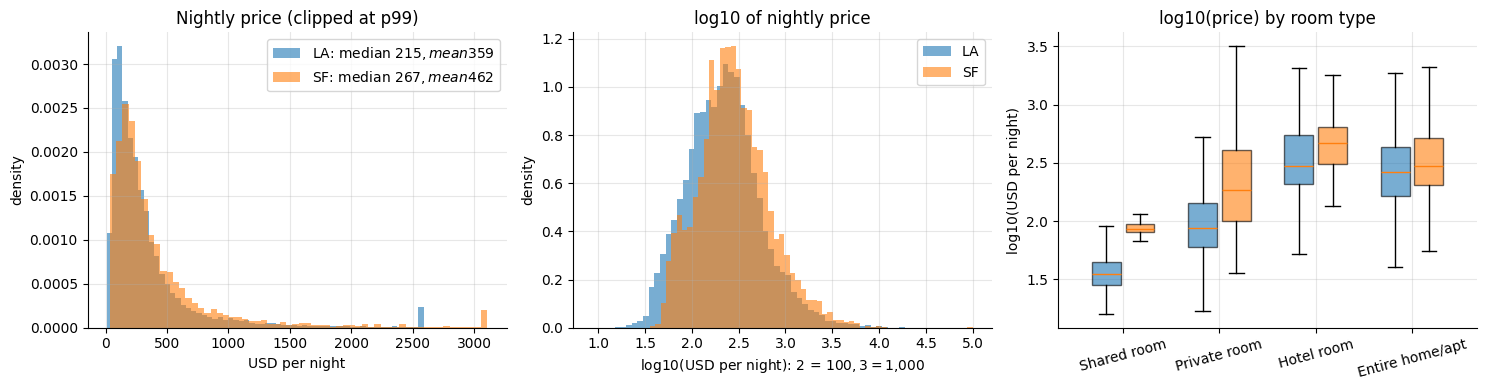

In [0]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for city in CITIES:
    p = pdf.loc[pdf.city == city, "price"].dropna()
    ax[0].hist(p.clip(upper=p.quantile(0.99)), bins=60, alpha=0.6, density=True, color=COLORS[city],
               label=f"{SHORT[city]}: median ${p.median():,.0f}, mean ${p.mean():,.0f}")
    ax[1].hist(np.log10(p), bins=60, alpha=0.6, density=True, color=COLORS[city], label=SHORT[city])
ax[0].set(title="Nightly price (clipped at p99)", xlabel="USD per night", ylabel="density")
ax[1].set(title="log10 of nightly price", xlabel="log10(USD per night): 2 = $100, 3 = $1,000", ylabel="density")
ax[0].legend(); ax[1].legend()
order = ["Shared room", "Private room", "Hotel room", "Entire home/apt"]
for i, city in enumerate(CITIES):
    g = pdf[pdf.city == city]
    bp = ax[2].boxplot([np.log10(g.loc[g.room_type == r, "price"].dropna()) for r in order],
                       positions=np.arange(4) + (i - 0.5) * 0.35, widths=0.3, patch_artist=True, showfliers=False)
    for b in bp["boxes"]:
        b.set_facecolor(COLORS[city]); b.set_alpha(0.6)
ax[2].set_xticks(range(4)); ax[2].set_xticklabels(order, rotation=15)
ax[2].set(title="log10(price) by room type", ylabel="log10(USD per night)")
plt.tight_layout(); plt.show()

**Other distributions.** Share of each city's listings per value or bin. Orange = SF, blue = LA.

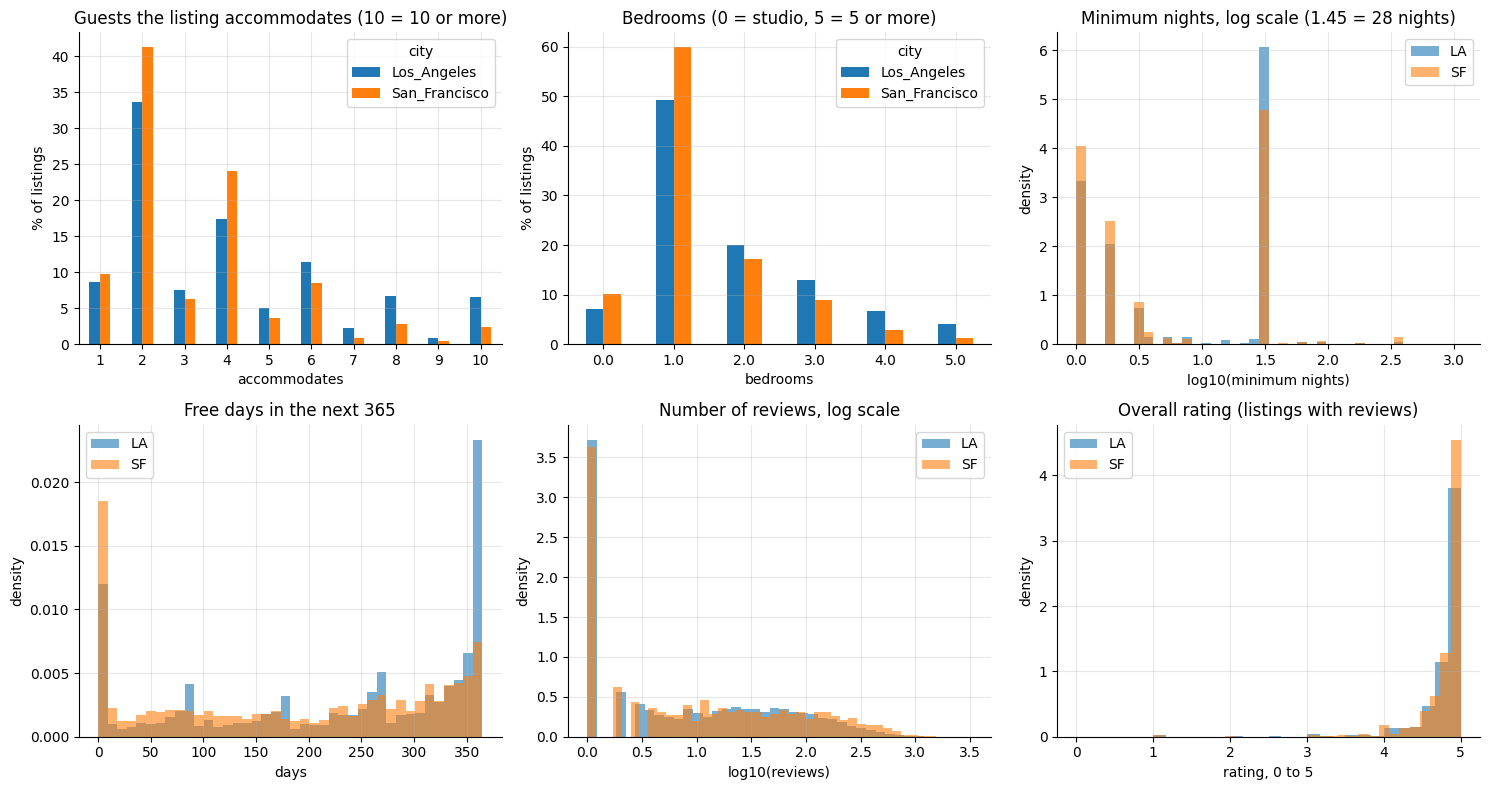

In [0]:
def hist_city(ax, col, bins, title, xlabel, log10=False, clip=None):
    for city in CITIES:
        s = pdf.loc[pdf.city == city, col].dropna()
        if clip is not None:
            s = s.clip(upper=clip)
        if log10:
            s = np.log10(s.clip(lower=1))
        ax.hist(s, bins=bins, alpha=0.6, density=True, color=COLORS[city], label=SHORT[city])
    ax.set(title=title, xlabel=xlabel, ylabel="density"); ax.legend()

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
acc = (pd.crosstab(pdf.accommodates.clip(upper=10), pdf.city, normalize="columns") * 100)
acc.plot.bar(ax=ax[0, 0], color=[COLORS[c] for c in acc.columns], rot=0)
ax[0, 0].set(title="Guests the listing accommodates (10 = 10 or more)", xlabel="accommodates", ylabel="% of listings")
bd = (pd.crosstab(pdf.bedrooms.clip(upper=5), pdf.city, normalize="columns") * 100)
bd.plot.bar(ax=ax[0, 1], color=[COLORS[c] for c in bd.columns], rot=0)
ax[0, 1].set(title="Bedrooms (0 = studio, 5 = 5 or more)", xlabel="bedrooms", ylabel="% of listings")
hist_city(ax[0, 2], "minimum_nights", 40, "Minimum nights, log scale (1.45 = 28 nights)", "log10(minimum nights)", log10=True)
hist_city(ax[1, 0], "availability_365", 40, "Free days in the next 365", "days", clip=365)
hist_city(ax[1, 1], "number_of_reviews", 40, "Number of reviews, log scale", "log10(reviews)", log10=True)
hist_city(ax[1, 2], "review_scores_rating", 30, "Overall rating (listings with reviews)", "rating, 0 to 5")
plt.tight_layout(); plt.show()

**Availability.** One row per city: share of listings with no free day in the next 30 / 365 days, with all 365 days free, and the median number of free days.

In [0]:
display(typed.groupBy("city").agg(
    F.round(100 * F.avg((F.col("availability_30") == 0).cast("int")), 1).alias("pct_zero_free_days_next_30"),
    F.round(100 * F.avg((F.col("availability_365") == 0).cast("int")), 1).alias("pct_zero_free_days_next_365"),
    F.round(100 * F.avg((F.col("availability_365") == 365).cast("int")), 1).alias("pct_all_365_days_free"),
    F.expr("percentile_approx(availability_365, 0.5)").alias("median_free_days_365"),
    F.round(100 * F.avg((F.col("has_availability") == F.lit(True)).cast("int")), 1).alias("pct_has_availability_flag_true")).orderBy("city"))

city,pct_zero_free_days_next_30,pct_zero_free_days_next_365,pct_all_365_days_free,median_free_days_365,pct_has_availability_flag_true
Los_Angeles,24.2,10.0,10.6,268,98.9
San_Francisco,38.2,13.7,1.6,201,96.5


**Categorical columns.** One row per (city, value) for the most common values: number of listings and share of the city.

In [0]:
def freq(col, top=10):
    w = Window.partitionBy("city")
    return (typed.groupBy("city", col).agg(F.count("*").alias("listings"))
            .withColumn("pct_of_city", F.round(100 * F.col("listings") / F.sum("listings").over(w), 1))
            .withColumn("rank", F.row_number().over(w.orderBy(F.desc("listings"))))
            .filter(F.col("rank") <= top).orderBy("city", "rank"))

print("room_type"); display(freq("room_type", 4))
print("property_type (top 10)"); display(freq("property_type", 10))

room_type


city,room_type,listings,pct_of_city,rank
Los_Angeles,Entire home/apt,32303,73.8,1
Los_Angeles,Private room,10755,24.6,2
Los_Angeles,Hotel room,412,0.9,3
Los_Angeles,Shared room,311,0.7,4
San_Francisco,Entire home/apt,4408,59.5,1
San_Francisco,Private room,2783,37.6,2
San_Francisco,Hotel room,173,2.3,3
San_Francisco,Shared room,41,0.6,4


property_type (top 10)


city,property_type,listings,pct_of_city,rank
Los_Angeles,Entire home,13425,30.7,1
Los_Angeles,Entire rental unit,10255,23.4,2
Los_Angeles,Private room in home,5595,12.8,3
Los_Angeles,Entire guesthouse,2919,6.7,4
Los_Angeles,Private room in rental unit,2250,5.1,5
Los_Angeles,Room in hotel,1566,3.6,6
Los_Angeles,Entire condo,1514,3.5,7
Los_Angeles,Entire guest suite,1131,2.6,8
Los_Angeles,Entire townhouse,750,1.7,9
Los_Angeles,Entire villa,547,1.2,10


In [0]:
print("neighbourhood_cleansed (top 8)"); display(freq("neighbourhood_cleansed", 8))
print("neighbourhood_group_cleansed (top 5)"); display(freq("neighbourhood_group_cleansed", 5))
print("host_is_superhost"); display(freq("host_is_superhost", 3))

neighbourhood_cleansed (top 8)


city,neighbourhood_cleansed,listings,pct_of_city,rank
Los_Angeles,Long Beach,1870,4.3,1
Los_Angeles,Hollywood,1635,3.7,2
Los_Angeles,Venice,1491,3.4,3
Los_Angeles,West Hollywood,1295,3.0,4
Los_Angeles,Santa Monica,1240,2.8,5
Los_Angeles,Downtown,1065,2.4,6
Los_Angeles,Exposition Park,923,2.1,7
Los_Angeles,Beverly Hills,801,1.8,8
San_Francisco,Downtown/Civic Center,1132,15.3,1
San_Francisco,South of Market,615,8.3,2


neighbourhood_group_cleansed (top 5)


city,neighbourhood_group_cleansed,listings,pct_of_city,rank
Los_Angeles,City of Los Angeles,21687,49.5,1
Los_Angeles,Other Cities,18007,41.1,2
Los_Angeles,Unincorporated Areas,4087,9.3,3
San_Francisco,null,7405,100.0,1


host_is_superhost


city,host_is_superhost,listings,pct_of_city,rank
Los_Angeles,false,26864,61.4,1
Los_Angeles,true,16917,38.6,2
San_Francisco,false,4053,54.7,1
San_Francisco,true,3352,45.3,2


**Category hygiene.** One row per (column, city): distinct values as written vs after lower-casing and trimming. Equal numbers mean no spelling/case duplicates.

In [0]:
rows = []
for col in ["room_type", "property_type", "neighbourhood_cleansed", "neighbourhood_group_cleansed"]:
    for city in CITIES:
        d = typed.filter(F.col("city") == city)
        rows.append({"column": col, "city": SHORT[city], "distinct_as_written": d.select(col).distinct().count(),
                     "distinct_after_lower_trim": d.select(F.lower(F.trim(F.col(col)))).distinct().count()})
display(pd.DataFrame(rows))

column,city,distinct_as_written,distinct_after_lower_trim
room_type,LA,4,4
room_type,SF,4,4
property_type,LA,91,91
property_type,SF,46,46
neighbourhood_cleansed,LA,264,264
neighbourhood_cleansed,SF,36,36
neighbourhood_group_cleansed,LA,3,3
neighbourhood_group_cleansed,SF,1,1


**Cardinality and transfer.** Number of values shared by the two cities for the location and type columns: a model cannot learn from a value it has never seen in another city.

In [0]:
rows = []
for col in ["property_type", "neighbourhood_cleansed", "room_type"]:
    a = set(r[0] for r in typed.filter(F.col("city") == CITIES[0]).select(col).distinct().collect())
    b = set(r[0] for r in typed.filter(F.col("city") == CITIES[1]).select(col).distinct().collect())
    rows.append({"column": col, "values_in_LA": len(a), "values_in_SF": len(b), "values_in_both": len(a & b)})
display(pd.DataFrame(rows))

column,values_in_LA,values_in_SF,values_in_both
property_type,91,46,45
neighbourhood_cleansed,264,36,1
room_type,4,4,4


## 7. Outliers

**Three statistical rules on price** (Lecture 6), one row per city. `iqr_*` = Tukey fence Q1 - 1.5 IQR / Q3 + 1.5 IQR; `z_*` = rows more than 3 standard deviations from the mean; `mad_*` = robust z-score above 3.5 (median and median absolute deviation). `n_*` = number of listings flagged.

In [0]:
rows = []
for city in CITIES:
    p = pdf.loc[pdf.city == city, "price"].dropna()
    q1, q3 = p.quantile(0.25), p.quantile(0.75)
    iqr = q3 - q1
    mu, sd, med = p.mean(), p.std(), p.median()
    mad = (p - med).abs().median()
    rows.append({"city": SHORT[city], "n_priced": len(p), "median": med, "mean": mu, "std": sd, "mad": mad,
                 "iqr_fence_high": q3 + 1.5 * iqr, "n_iqr": int(((p < q1 - 1.5 * iqr) | (p > q3 + 1.5 * iqr)).sum()),
                 "z_fence_high": mu + 3 * sd, "n_z": int(((p - mu).abs() / sd > 3).sum()),
                 "mad_fence_high": med + 3.5 * mad / 0.6745, "n_mad": int((0.6745 * (p - med).abs() / mad > 3.5).sum())})
display(pd.DataFrame(rows).round(1))

city,n_priced,median,mean,std,mad,iqr_fence_high,n_iqr,z_fence_high,n_z,mad_fence_high,n_mad
LA,36687,214.6,359.3,668.9,114.2,766.0,3088,2366.0,431,807.4,2855
SF,5691,267.0,461.9,1466.0,134.5,966.6,497,4859.9,23,964.9,498


**The 20 most expensive listings.** One row per listing; `price_per_guest` = nightly price divided by `accommodates`.

In [0]:
display(typed.filter(F.col("price").isNotNull()).orderBy(F.desc("price")).select(
    "city", "id", "room_type", "property_type", "accommodates", "bedrooms", "minimum_nights",
    "price", F.round("price_per_guest", 1).alias("price_per_guest")).limit(20))

city,id,room_type,property_type,accommodates,bedrooms,minimum_nights,price,price_per_guest
San_Francisco,35195461,Private room,Room in boutique hotel,2,0.0,1,99999.0,49999.5
Los_Angeles,1457305618869144492,Entire home/apt,Entire home,12,6.0,200,37787.53,3149.0
Los_Angeles,25870842,Entire home/apt,Entire villa,12,7.0,3,20583.33,1715.3
Los_Angeles,1363305939461956001,Entire home/apt,Entire villa,16,9.0,6,20277.33,1267.3
Los_Angeles,1766248091807918339,Entire home/apt,Entire home,14,7.0,3,18690.0,1335.0
Los_Angeles,20471072,Entire home/apt,Entire villa,16,9.0,30,18395.85,1149.7
Los_Angeles,1079908245408870997,Entire home/apt,Entire home,14,6.0,4,18117.0,1294.1
Los_Angeles,1744612157503736949,Entire home/apt,Entire home,16,9.0,3,17117.66,1069.9
Los_Angeles,1569397151095732791,Entire home/apt,Entire home,10,5.0,5,15490.0,1549.0
Los_Angeles,1136418613533078238,Entire home/apt,Entire home,16,9.0,31,14553.21,909.6


### Classify, do not delete
Every priced listing gets one `price_class`. Rules (first match wins): `no_price` = no price; `placeholder` = price per guest >= $2,500 or price >= $99,999 (a number typed to block a listing); `high_explained` = above the Tukey fence of **log price within city x room type** and `accommodates >= 8` or `bedrooms >= 4` (a real large home); `high_unexplained` = above the fence, small property; `low` = below the lower fence; `normal`. Nothing is deleted; the training-eligible rows are those that are not `no_price` / `placeholder`.

In [0]:
fences = (typed.filter(F.col("price").isNotNull()).groupBy("city", "room_type").agg(
              F.expr("percentile_approx(ln(price), 0.25)").alias("q1"),
              F.expr("percentile_approx(ln(price), 0.75)").alias("q3"))
          .withColumn("fence_low", F.col("q1") - 1.5 * (F.col("q3") - F.col("q1")))
          .withColumn("fence_high", F.col("q3") + 1.5 * (F.col("q3") - F.col("q1")))
          .select("city", "room_type", "fence_low", "fence_high"))

log_price = F.log("price")
classified = (typed.join(F.broadcast(fences), on=["city", "room_type"], how="left")
    .withColumn("price_class",
        F.when(F.col("price").isNull(), "no_price")
         .when((F.col("price_per_guest") >= 2500) | (F.col("price") >= 99999), "placeholder")
         .when((log_price > F.col("fence_high")) & ((F.col("accommodates") >= 8) | (F.coalesce(F.col("bedrooms"), F.lit(0)) >= 4)), "high_explained")
         .when(log_price > F.col("fence_high"), "high_unexplained")
         .when(log_price < F.col("fence_low"), "low")
         .otherwise("normal")))

classified.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(f"{CATALOG}.{SCHEMA}.listings_classified")
classified = spark.table(f"{CATALOG}.{SCHEMA}.listings_classified")

pdf = pdf.merge(classified.select("city", "id", "price_class").toPandas(), on=["city", "id"], how="left")

**Price classes.** One row per class, one column per city: number of listings, then share of the city's listings.

In [0]:
order_cls = ["normal", "high_explained", "high_unexplained", "low", "placeholder", "no_price"]
cnt = pdf.groupby(["price_class", "city"]).size().unstack("city").reindex(order_cls).fillna(0).astype(int)
pct = (100 * cnt / cnt.sum()).round(2)
display(cnt.join(pct, lsuffix="_listings", rsuffix="_pct").rename_axis("price_class").reset_index())

price_class,Los_Angeles_listings,San_Francisco_listings,Los_Angeles_pct,San_Francisco_pct
normal,35700,5555,81.54,75.02
high_explained,627,62,1.43,0.84
high_unexplained,336,57,0.77,0.77
low,13,2,0.03,0.03
placeholder,11,15,0.03,0.2
no_price,7094,1714,16.2,23.15


**Where the classes sit.** Each dot is a listing: horizontal = guests (jittered), vertical = nightly price on a log scale. Black = placeholders.

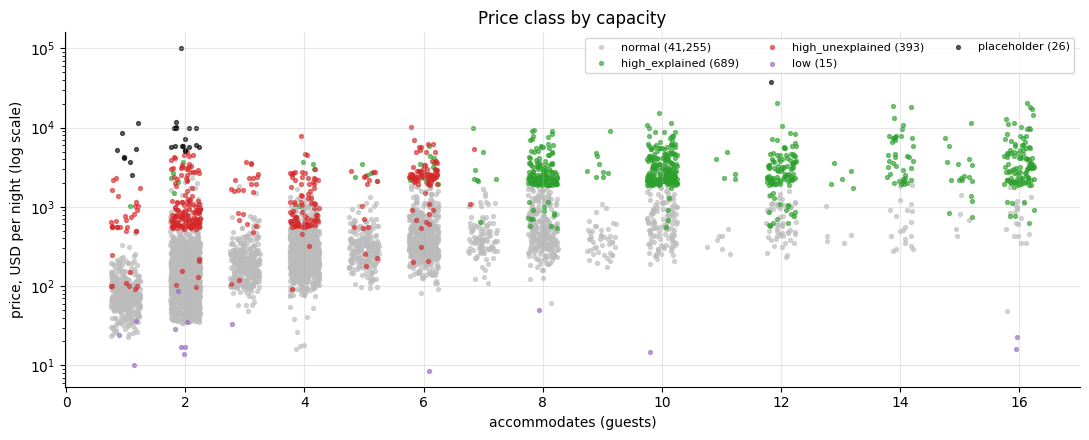

In [0]:
fig, ax = plt.subplots(figsize=(11, 4.5))
pal = {"normal": "#bbbbbb", "high_explained": "#2ca02c", "high_unexplained": "#d62728", "low": "#9467bd", "placeholder": "black"}
rng = np.random.default_rng(0)
for k, col in pal.items():
    g = pdf[pdf.price_class == k]
    if k == "normal":
        g = g.sample(min(len(g), 4000), random_state=0)
    ax.scatter(g.accommodates + rng.uniform(-0.25, 0.25, len(g)), g.price, s=8, c=col, alpha=0.6, label=f"{k} ({(pdf.price_class == k).sum():,})")
ax.set_yscale("log"); ax.legend(ncol=3, fontsize=8)
ax.set(title="Price class by capacity", xlabel="accommodates (guests)", ylabel="price, USD per night (log scale)")
plt.tight_layout(); plt.show()

**Placeholders.** One row per placeholder listing, most expensive first.

In [0]:
display(classified.filter(F.col("price_class") == "placeholder").orderBy(F.desc("price")).select(
    "city", "id", "room_type", "property_type", "accommodates", "bedrooms", "price", F.round("price_per_guest", 0).alias("price_per_guest")))

city,id,room_type,property_type,accommodates,bedrooms,price,price_per_guest
San_Francisco,35195461,Private room,Room in boutique hotel,2,0.0,99999.0,50000.0
Los_Angeles,1457305618869144492,Entire home/apt,Entire home,12,6.0,37787.53,3149.0
San_Francisco,36002932,Private room,Room in boutique hotel,2,1.0,11870.0,5935.0
Los_Angeles,53064422,Entire home/apt,Tiny home,1,null,11412.0,11412.0
Los_Angeles,906740803637144085,Private room,Room in hotel,2,2.0,10280.8,5140.0
Los_Angeles,836725106298539007,Private room,Room in hotel,2,1.0,10000.0,5000.0
San_Francisco,36148199,Private room,Room in hotel,2,1.0,10000.0,5000.0
San_Francisco,36002747,Private room,Room in boutique hotel,2,1.0,10000.0,5000.0
San_Francisco,36148137,Private room,Room in hotel,2,1.0,10000.0,5000.0
San_Francisco,706622701100970112,Private room,Room in hotel,1,1.0,8583.4,8583.0


**Outliers in other numeric columns.** One row per (column, city), Tukey rule on the raw values: the fences, how many listings fall outside, their share, and the column's min and max.

In [0]:
rows = []
for col in ["accommodates", "bedrooms", "beds", "bathrooms_num", "n_amenities", "minimum_nights", "maximum_nights", "availability_365",
            "number_of_reviews", "reviews_per_month", "host_listings_count", "calculated_host_listings_count", "hosts_time_as_host_years"]:
    for city in CITIES:
        s = pdf.loc[pdf.city == city, col].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
        n_out = int(((s < lo) | (s > hi)).sum())
        rows.append({"column": col, "city": SHORT[city], "q1": q1, "q3": q3, "fence_low": lo, "fence_high": hi,
                     "n_outside": n_out, "pct_outside": round(100 * n_out / len(s), 1), "min": s.min(), "max": s.max()})
display(pd.DataFrame(rows))

column,city,q1,q3,fence_low,fence_high,n_outside,pct_outside,min,max
accommodates,LA,2.0,6.0,-4.0,12.0,734,1.7,1.0,16.0
accommodates,SF,2.0,4.0,-1.0,7.0,412,5.6,1.0,16.0
bedrooms,LA,1.0,2.0,-0.5,3.5,4681,10.7,0.0,24.0
bedrooms,SF,1.0,2.0,-0.5,3.5,293,4.0,0.0,23.0
beds,LA,1.0,3.0,-2.0,6.0,986,2.3,1.0,50.0
beds,SF,1.0,2.0,-0.5,3.5,650,9.1,1.0,26.0
bathrooms_num,LA,1.0,2.0,-0.5,3.5,2351,5.4,0.0,24.0
bathrooms_num,SF,1.0,1.5,0.25,2.25,602,8.1,0.0,27.0
n_amenities,LA,25.0,51.0,-14.0,90.0,96,0.2,0.0,126.0
n_amenities,SF,22.0,46.0,-14.0,82.0,9,0.1,0.0,91.0


**Reading.**
- Placeholders are rare (26 listings) but extreme: mostly one- or two-guest rooms and units at $5,000 to $99,999 (9 of the 20 listed are hotel rooms; five are similar SF entire rental units at $5,700 to $7,100 for two guests, worth a closer look); one $37,788 six-bedroom house is borderline, so the rule is a judgement.
- The `high_*` classes (about 700 and 400 listings) are the real right tail of the market (large homes, prime locations), not errors: kept and flagged.
- Sentinels: `maximum_nights = 1125` means "no limit" (about 30 % of listings) and `minimum_nights > 365` appears in 28 listings: cap or null them. `bedrooms = 0` is a valid studio. Hosts with more than 100 listings are commercial operators.

## 8. What `price` really is: a price quote

`price` equals `price_quote_price_per_night`, the per-night figure of a price quote for one concrete future stay (`price_quote_checkin_date` to `price_quote_checkout_date`). The tables below look at those stays.

In [0]:
clean = classified.filter(F.col("price_class").isin("normal", "high_explained", "high_unexplained", "low"))   # priced, not a placeholder
print("training-eligible listings:", clean.groupBy("city").count().orderBy("city").collect())

training-eligible listings: [Row(city='Los_Angeles', count=36676), Row(city='San_Francisco', count=5676)]


**Is `price` the quote's nightly price?** One row per city: % of priced listings where the two columns are equal to a tenth of a cent.

In [0]:
display(typed.filter(F.col("price").isNotNull()).groupBy("city").agg(
    F.round(100 * F.avg((F.abs(F.col("price") - F.col("price_quote_price_per_night")) < 0.001).cast("int")), 3).alias("pct_price_equals_quote_price_per_night"),
    F.count("*").alias("priced_listings")).orderBy("city"))

city,pct_price_equals_quote_price_per_night,priced_listings
Los_Angeles,100.0,36687
San_Francisco,100.0,5691


**Length of the quoted stay.** One row per (city, quoted nights): number of priced listings and their share of the city's priced listings.

In [0]:
nights = (F.when(F.col("quote_nights") == 1, "1) 1 night").when(F.col("quote_nights") == 2, "2) 2 nights")
           .when(F.col("quote_nights") == 3, "3) 3 nights").when(F.col("quote_nights") <= 7, "4) 4-7 nights")
           .when(F.col("quote_nights") <= 27, "5) 8-27 nights").when(F.col("quote_nights") <= 31, "6) 28-31 nights")
           .otherwise("7) 32+ nights"))
display(typed.filter(F.col("price").isNotNull()).withColumn("quoted_stay", nights)
    .groupBy("city", "quoted_stay").agg(F.count("*").alias("listings"))
    .withColumn("pct_of_city_priced", F.round(100 * F.col("listings") / F.sum("listings").over(Window.partitionBy("city")), 1))
    .orderBy("city", "quoted_stay"))

city,quoted_stay,listings,pct_of_city_priced
Los_Angeles,1) 1 night,8631,23.5
Los_Angeles,2) 2 nights,6787,18.5
Los_Angeles,3) 3 nights,2526,6.9
Los_Angeles,4) 4-7 nights,1461,4.0
Los_Angeles,5) 8-27 nights,565,1.5
Los_Angeles,6) 28-31 nights,16305,44.4
Los_Angeles,7) 32+ nights,412,1.1
San_Francisco,1) 1 night,1609,28.3
San_Francisco,2) 2 nights,1232,21.6
San_Francisco,3) 3 nights,488,8.6


**Quoted stay vs host's minimum stay.** One row per (city, `minimum_nights` bucket): number of listings, median quoted nights, % quoted as a monthly stay, median price.

In [0]:
min_bucket = (F.when(F.col("minimum_nights").isNull(), "0) unknown").when(F.col("minimum_nights") == 1, "1) 1 night")
              .when(F.col("minimum_nights") == 2, "2) 2 nights").when(F.col("minimum_nights") == 3, "3) 3 nights")
              .when(F.col("minimum_nights") <= 7, "4) 4-7 nights").when(F.col("minimum_nights") <= 27, "5) 8-27 nights")
              .otherwise("6) 28+ nights"))
display(typed.filter(F.col("price").isNotNull()).withColumn("minimum_nights_bucket", min_bucket)
    .groupBy("city", "minimum_nights_bucket").agg(
        F.count("*").alias("listings"),
        F.expr("percentile_approx(quote_nights, 0.5)").alias("median_quoted_nights"),
        F.round(100 * F.avg(F.col("quote_is_monthly").cast("int")), 1).alias("pct_quoted_as_monthly"),
        F.expr("percentile_approx(price, 0.5)").alias("median_price_usd"))
    .orderBy("city", "minimum_nights_bucket"))
print("% of priced listings where the quoted stay is at least minimum_nights:")
display(typed.filter(F.col("price").isNotNull() & F.col("minimum_nights").isNotNull()).groupBy("city").agg(
    F.round(100 * F.avg((F.col("quote_nights") >= F.col("minimum_nights")).cast("int")), 2).alias("pct_quote_at_least_minimum_nights")))

city,minimum_nights_bucket,listings,median_quoted_nights,pct_quoted_as_monthly,median_price_usd
Los_Angeles,0) unknown,19,1,10.5,213.5
Los_Angeles,1) 1 night,10108,1,0.9,270.06
Los_Angeles,2) 2 nights,6240,2,1.3,309.1
Los_Angeles,3) 3 nights,2131,3,2.2,321.09
Los_Angeles,4) 4-7 nights,1267,5,3.6,260.86
Los_Angeles,5) 8-27 nights,520,14,8.8,176.16
Los_Angeles,6) 28+ nights,16402,30,99.8,138.03
San_Francisco,0) unknown,11,2,0.0,240.12
San_Francisco,1) 1 night,1949,1,0.3,367.0
San_Francisco,2) 2 nights,1155,2,0.3,321.0


% of priced listings where the quoted stay is at least minimum_nights:


city,pct_quote_at_least_minimum_nights
Los_Angeles,99.99
San_Francisco,100.0


**Monthly vs short stays, like for like.** One row per (city, room type, `accommodates`) with at least 15 listings of each stay type: median price of each and their ratio (`monthly_to_short_ratio`). Second table: distribution of that ratio over all such cells.

In [0]:
v = pdf[pdf.price_class.isin(["normal", "high_explained", "high_unexplained", "low"])].copy()   # priced, not a placeholder
cells = (v.groupby(["city", "room_type", "accommodates", "stay_type"])["price"]
           .agg(listings="size", median_price="median").unstack("stay_type"))
cells.columns = [f"{a}_{b}" for a, b in cells.columns]
cells = cells.dropna()
cells = cells[(cells.listings_short >= 15) & (cells.listings_monthly >= 15)].copy()
cells["monthly_to_short_ratio"] = cells.median_price_monthly / cells.median_price_short
display(cells.reset_index().sort_values("listings_short", ascending=False).head(12).round(2))
display(cells["monthly_to_short_ratio"].describe().round(2).to_frame("monthly_to_short_ratio").rename_axis("statistic").reset_index())

city,room_type,accommodates,listings_monthly,listings_short,median_price_monthly,median_price_short,monthly_to_short_ratio
Los_Angeles,Entire home/apt,2,3486.0,3096.0,119.67,213.76,0.56
Los_Angeles,Entire home/apt,4,2564.0,3073.0,172.9,291.2,0.59
Los_Angeles,Private room,2,2366.0,2887.0,59.84,124.0,0.48
Los_Angeles,Entire home/apt,6,1554.0,2613.0,281.08,402.0,0.7
Los_Angeles,Entire home/apt,8,870.0,1623.0,443.38,492.0,0.9
Los_Angeles,Entire home/apt,3,1049.0,1262.0,138.03,234.75,0.59
Los_Angeles,Entire home/apt,5,676.0,1080.0,212.26,333.0,0.64
San_Francisco,Private room,2,296.0,893.0,72.51,230.0,0.32
Los_Angeles,Entire home/apt,10,442.0,785.0,837.47,681.36,1.23
Los_Angeles,Private room,1,1603.0,747.0,62.13,88.0,0.71


statistic,monthly_to_short_ratio
count,32.0
mean,0.71
std,0.34
min,0.24
25%,0.52
50%,0.62
75%,0.73
max,1.86


**Lead time.** One row per (city, how many days after the snapshot the quoted stay starts), short-stay listings only: number of listings and median price. Shows how much the quote date moves the price.

In [0]:
lead = (F.when(F.col("quote_lead_days") <= 0, "1) same day or earlier").when(F.col("quote_lead_days") <= 3, "2) 1-3 days")
         .when(F.col("quote_lead_days") <= 7, "3) 4-7 days").when(F.col("quote_lead_days") <= 14, "4) 8-14 days")
         .when(F.col("quote_lead_days") <= 30, "5) 15-30 days").when(F.col("quote_lead_days") <= 60, "6) 31-60 days")
         .when(F.col("quote_lead_days") <= 120, "7) 61-120 days").otherwise("8) 121+ days"))
display(clean.filter(F.col("stay_type") == "short").withColumn("quoted_stay_starts", lead)
    .groupBy("city", "quoted_stay_starts").agg(F.count("*").alias("listings"), F.expr("percentile_approx(price, 0.5)").alias("median_price_usd"))
    .orderBy("city", "quoted_stay_starts"))

city,quoted_stay_starts,listings,median_price_usd
Los_Angeles,1) same day or earlier,6599,285.6
Los_Angeles,2) 1-3 days,3955,282.16
Los_Angeles,3) 4-7 days,3617,300.0
Los_Angeles,4) 8-14 days,2346,289.86
Los_Angeles,5) 15-30 days,1835,269.5
Los_Angeles,6) 31-60 days,780,235.0
Los_Angeles,7) 61-120 days,722,244.0
Los_Angeles,8) 121+ days,402,265.0
San_Francisco,1) same day or earlier,309,937.0
San_Francisco,2) 1-3 days,622,458.0


**Reading.** `price` is not one comparable number per listing: each listing was quoted for a different stay (check-in from today to a year ahead, 1 to 365 nights). The stay is the host's minimum stay, so **`minimum_nights` already encodes the quote conditions**. Listings with `minimum_nights >= 28` are monthly stays priced at about 60 % of comparable short stays per night (median ratio 0.62): statistics must be reported per stay type, and `is_monthly_rental` is a strong legitimate feature. The quote date adds noise that differs by city: in LA the short-stay medians move between $235 and $300 across lead-time groups (about plus or minus 12 %), in SF between $276 and $937 (same-day quotes are the most expensive, 309 listings), so part of SF short-stay prices cannot be explained from listing features.

## 9. Validity and consistency checks

One row per rule: how many listings **violate** it in each city (0 = rule holds everywhere). Rules are common-sense limits and relations between columns.

In [0]:
in_box = (((F.col("city") == "Los_Angeles") & F.col("latitude").between(33.0, 35.0) & F.col("longitude").between(-119.5, -117.0)) |
          ((F.col("city") == "San_Francisco") & F.col("latitude").between(37.6, 37.9) & F.col("longitude").between(-122.6, -122.3)))
rules = [
    ("price is not positive", F.col("price") <= 0),
    ("accommodates < 1", F.col("accommodates") < 1),
    ("bedrooms > accommodates", F.col("bedrooms") > F.col("accommodates")),
    ("bathrooms = 0", F.col("bathrooms_num") == 0),
    ("minimum_nights < 1", F.col("minimum_nights") < 1),
    ("minimum_nights > maximum_nights", F.col("minimum_nights") > F.col("maximum_nights")),
    ("minimum_nights > 365", F.col("minimum_nights") > 365),
    ("maximum_nights >= 1125 (platform 'no limit' value)", F.col("maximum_nights") >= 1125),
    ("availability_30 > availability_60", F.col("availability_30") > F.col("availability_60")),
    ("availability_60 > availability_90", F.col("availability_60") > F.col("availability_90")),
    ("availability_90 > availability_365", F.col("availability_90") > F.col("availability_365")),
    ("availability_365 outside 0..365", (F.col("availability_365") < 0) | (F.col("availability_365") > 365)),
    ("estimated_occupancy_l365d outside 0..365", (F.col("estimated_occupancy_l365d") < 0) | (F.col("estimated_occupancy_l365d") > 365)),
    ("reviews in last 12 months > all reviews", F.col("number_of_reviews_ltm") > F.col("number_of_reviews")),
    ("reviews in last 30 days > last 12 months", F.col("number_of_reviews_l30d") > F.col("number_of_reviews_ltm")),
    ("rating outside 0..5", (F.col("review_scores_rating") < 0) | (F.col("review_scores_rating") > 5)),
    ("no reviews but a rating exists", (F.col("number_of_reviews") == 0) & F.col("review_scores_rating").isNotNull()),
    ("has reviews but no rating", (F.col("number_of_reviews") > 0) & F.col("review_scores_rating").isNull()),
    ("first_review after last_review", F.col("first_review") > F.col("last_review")),
    ("last_review after the scrape date", F.col("last_review") > F.col("last_scraped")),
    ("first_review before 2008 (Airbnb did not exist)", F.col("first_review") < F.lit("2008-01-01").cast("date")),
    ("latitude or longitude missing", F.col("latitude").isNull() | F.col("longitude").isNull()),
    ("coordinates outside the city's bounding box", ~in_box),
    ("host listing counts do not add up (entire + private + shared != total)",
     F.col("calculated_host_listings_count") != (F.col("calculated_host_listings_count_entire_homes")
                                                  + F.col("calculated_host_listings_count_private_rooms")
                                                  + F.col("calculated_host_listings_count_shared_rooms"))),
    ("quoted stay shorter than minimum_nights", F.col("quote_nights") < F.col("minimum_nights")),
    ("price per guest >= $2,500 (placeholder rule)", F.col("price_per_guest") >= 2500),
]
ids_ = [f"R{i:02d}" for i in range(len(rules))]
res = typed.groupBy("city").agg(*[F.sum(F.coalesce(cond, F.lit(False)).cast("int")).alias(i) for i, (_, cond) in zip(ids_, rules)]).toPandas().set_index("city")
checks = pd.DataFrame({"rule": [name for name, _ in rules],
                       "violations_LA": [int(res.loc["Los_Angeles", i]) for i in ids_],
                       "violations_SF": [int(res.loc["San_Francisco", i]) for i in ids_]})
checks["pct_LA"] = (100 * checks.violations_LA / n_city["Los_Angeles"]).round(2)
checks["pct_SF"] = (100 * checks.violations_SF / n_city["San_Francisco"]).round(2)
display(checks)

rule,violations_LA,violations_SF,pct_LA,pct_SF
price is not positive,0,0,0.0,0.0
accommodates < 1,0,0,0.0,0.0
bedrooms > accommodates,203,35,0.46,0.47
bathrooms = 0,172,50,0.39,0.68
minimum_nights < 1,0,0,0.0,0.0
minimum_nights > maximum_nights,0,1,0.0,0.01
minimum_nights > 365,23,5,0.05,0.07
maximum_nights >= 1125 (platform 'no limit' value),13265,2198,30.3,29.68
availability_30 > availability_60,0,0,0.0,0.0
availability_60 > availability_90,0,0,0.0,0.0


## 10. Relationships with price

Only training-eligible listings (priced, not a placeholder). **Correlation with price**: one row per candidate numeric column; `pearson_*` = linear correlation with price, `spearman_*` = rank correlation (not distorted by huge prices); columns per city. Sorted by LA Spearman.

In [0]:
FEAT_NUM = ["accommodates", "bedrooms", "beds", "bathrooms_num", "n_amenities", "minimum_nights", "host_listings_count",
            "calculated_host_listings_count", "hosts_time_as_host_years", "latitude", "longitude", "availability_365",
            "number_of_reviews", "reviews_per_month", "review_scores_rating", "review_scores_value", "estimated_occupancy_l365d"]
rows = []
for city in CITIES:
    d = v[v.city == city]
    for f in FEAT_NUM:
        rows.append({"feature": f, "city": SHORT[city], "pearson": d[f].corr(d["price"]), "spearman": d[f].corr(d["price"], method="spearman")})
corr = pd.DataFrame(rows).pivot(index="feature", columns="city", values=["pearson", "spearman"])
corr.columns = [f"{a}_{b}" for a, b in corr.columns]
display(corr.reset_index().sort_values("spearman_LA", ascending=False).round(2))

feature,pearson_LA,pearson_SF,spearman_LA,spearman_SF
accommodates,0.47,0.48,0.73,0.6
bedrooms,0.5,0.36,0.66,0.39
beds,0.42,0.41,0.65,0.51
bathrooms_num,0.61,0.24,0.57,0.24
n_amenities,0.17,0.11,0.35,0.15
reviews_per_month,-0.01,-0.03,0.25,0.13
review_scores_rating,0.07,0.08,0.09,0.17
number_of_reviews,-0.05,-0.12,0.08,-0.12
estimated_occupancy_l365d,-0.09,-0.2,0.05,-0.16
review_scores_value,0.04,0.04,0.01,0.09


**Correlation matrix between the numeric columns** (Spearman, one panel per city). Red = move together, blue = opposite; many dark cells off the diagonal mean the columns carry the same information.

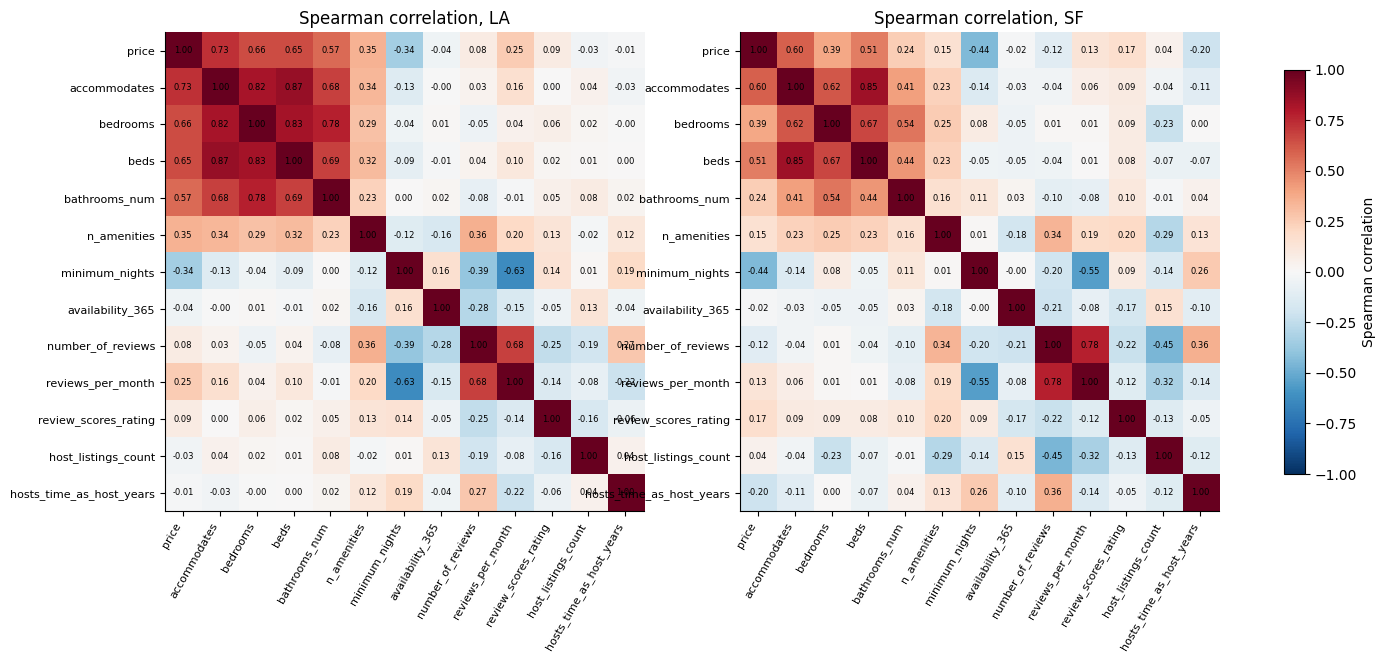

In [0]:
HEAT = ["price", "accommodates", "bedrooms", "beds", "bathrooms_num", "n_amenities", "minimum_nights", "availability_365",
        "number_of_reviews", "reviews_per_month", "review_scores_rating", "host_listings_count", "hosts_time_as_host_years"]
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
for ax, city in zip(axes, CITIES):
    m = v.loc[v.city == city, HEAT].corr(method="spearman")
    im = ax.imshow(m, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(HEAT))); ax.set_xticklabels(HEAT, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(HEAT))); ax.set_yticklabels(HEAT, fontsize=8)
    for i in range(len(HEAT)):
        for j in range(len(HEAT)):
            ax.text(j, i, f"{m.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
    ax.set_title(f"Spearman correlation, {SHORT[city]}"); ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.7, label="Spearman correlation")
plt.show()

**Price vs capacity.** Each dot is a listing (colour = room type); black line = median price per capacity. Left: dollars, right: log scale. One row per city.

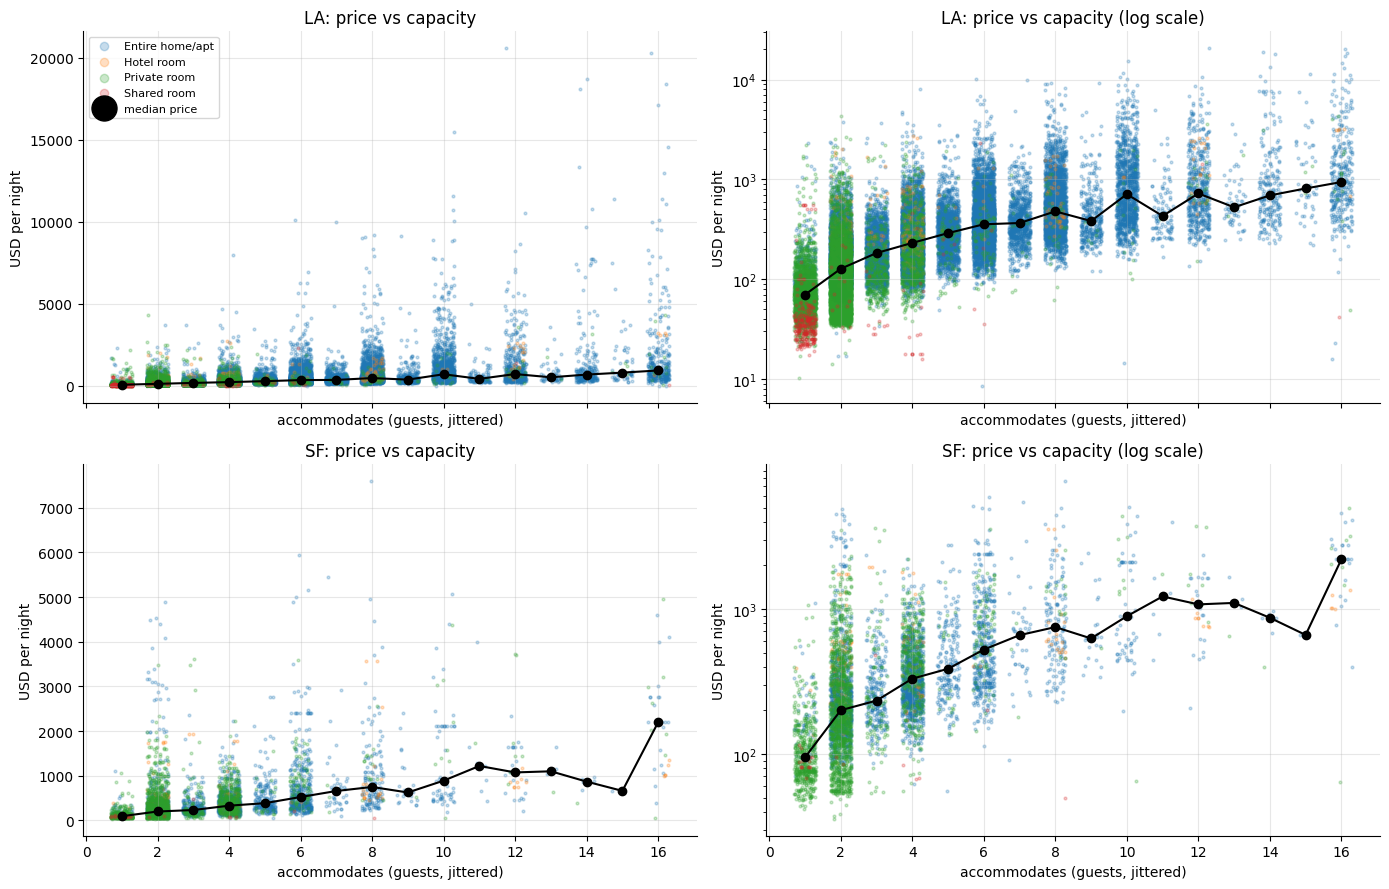

In [0]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
rng = np.random.default_rng(42)
for r, city in enumerate(CITIES):
    d = v[v.city == city]
    med = d.groupby("accommodates")["price"].median()
    for c, logy in enumerate([False, True]):
        ax = axes[r, c]
        for rt, g in d.groupby("room_type"):
            ax.scatter(g.accommodates + rng.uniform(-0.3, 0.3, len(g)), g.price, s=4, alpha=0.25, label=rt)
        ax.plot(med.index, med.values, color="black", marker="o", label="median price")
        if logy:
            ax.set_yscale("log")
        ax.set(title=f"{SHORT[city]}: price vs capacity" + (" (log scale)" if logy else ""), xlabel="accommodates (guests, jittered)", ylabel="USD per night")
axes[0, 0].legend(fontsize=8, markerscale=3)
plt.tight_layout(); plt.show()

**Price by room type and stay type.** One row per (city, room type, stay type): listings, median, quartiles of price.

In [0]:
t = (v.groupby(["city", "room_type", "stay_type"])["price"]
       .agg(listings="size", q1=lambda s: s.quantile(.25), median="median", q3=lambda s: s.quantile(.75)).round(0).reset_index())
display(t)

city,room_type,stay_type,listings,q1,median,q3
Los_Angeles,Entire home/apt,monthly,11906,120.0,177.0,305.0
Los_Angeles,Entire home/apt,short,15247,231.0,330.0,505.0
Los_Angeles,Hotel room,monthly,24,210.0,265.0,307.0
Los_Angeles,Hotel room,short,371,209.0,301.0,573.0
Los_Angeles,Private room,monthly,4284,49.0,63.0,84.0
Los_Angeles,Private room,short,4538,87.0,125.0,194.0
Los_Angeles,Shared room,monthly,187,25.0,30.0,35.0
Los_Angeles,Shared room,short,100,39.0,46.0,100.0
San_Francisco,Entire home/apt,monthly,1333,156.0,206.0,294.0
San_Francisco,Entire home/apt,short,1885,270.0,394.0,689.0


**Neighbourhoods by median price** (at least 30 short-stay listings). One row per neighbourhood: listings, median price, mean price. Top 8 and bottom 4 per city.

In [0]:
for city in CITIES:
    g = (v[(v.city == city) & (v.stay_type == "short")].groupby("neighbourhood_cleansed")["price"]
           .agg(listings="size", median_price="median", mean_price="mean").query("listings >= 30").sort_values("median_price", ascending=False).round(0))
    print(f"{SHORT[city]}: {len(g)} neighbourhoods with at least 30 short-stay listings")
    display(pd.concat([g.head(8), g.tail(4)]).reset_index())

LA: 128 neighbourhoods with at least 30 short-stay listings


neighbourhood_cleansed,listings,median_price,mean_price
Bel-Air,36,2120.0,2650.0
Beverly Crest,85,1499.0,1896.0
Malibu,281,1030.0,1873.0
Hollywood Hills West,226,1012.0,1387.0
Avalon,202,770.0,835.0
Unincorporated Santa Monica Mountains,160,640.0,988.0
Valley Village,39,591.0,616.0
Fairfax,78,579.0,805.0
Walnut,45,108.0,198.0
Willowbrook,31,107.0,232.0


SF: 29 neighbourhoods with at least 30 short-stay listings


neighbourhood_cleansed,listings,median_price,mean_price
North Beach,173,829.0,914.0
Financial District,192,598.0,906.0
Russian Hill,121,564.0,774.0
Pacific Heights,53,557.0,1080.0
Marina,137,457.0,642.0
Castro/Upper Market,126,433.0,698.0
South of Market,214,421.0,558.0
Noe Valley,88,398.0,528.0
Visitacion Valley,38,214.0,266.0
Crocker Amazon,32,213.0,260.0


**Property types by price.** One row per (city, property type) among the 8 most common: listings and median short-stay price.

In [0]:
for city in CITIES:
    d = v[(v.city == city) & (v.stay_type == "short")]
    top = d.property_type.value_counts().head(8).index
    t = d[d.property_type.isin(top)].groupby("property_type")["price"].agg(listings="size", median_price="median").sort_values("listings", ascending=False).round(0)
    print(SHORT[city]); display(t.reset_index())

LA


property_type,listings,median_price
Entire home,7021,416.0
Entire rental unit,4175,298.0
Private room in home,2570,104.0
Entire guesthouse,1434,220.0
Room in hotel,1275,280.0
Entire guest suite,663,198.0
Entire condo,546,333.0
Entire townhouse,379,392.0


SF


property_type,listings,median_price
Room in hotel,856,464.0
Entire rental unit,538,377.0
Entire home,480,539.0
Private room in home,458,168.0
Entire condo,357,529.0
Entire guest suite,344,270.0
Private room in rental unit,123,197.0
Room in boutique hotel,111,445.0


**Price on the map.** Each dot is a listing at its coordinates; colour = log10 of nightly price (2 = $100, 3 = $1,000).

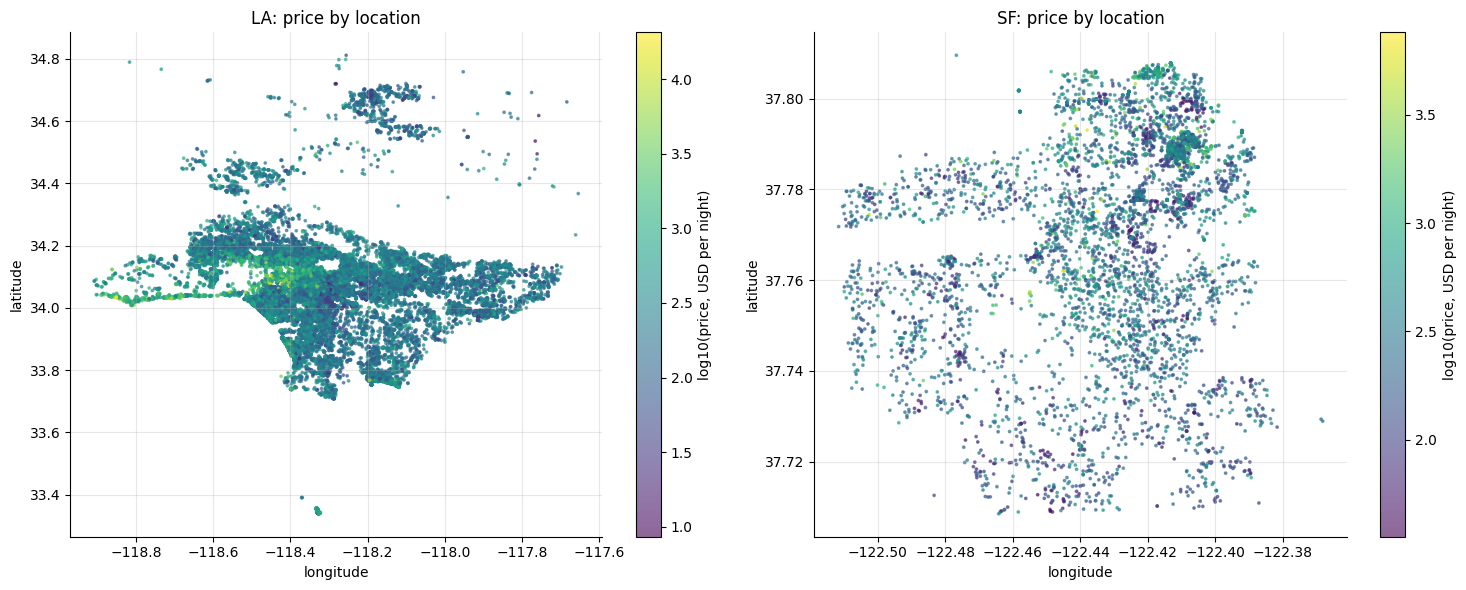

In [0]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, city in zip(axes, CITIES):
    d = v[v.city == city]
    sc = ax.scatter(d.longitude, d.latitude, c=np.log10(d.price), s=3, cmap="viridis", alpha=0.6)
    fig.colorbar(sc, ax=ax, label="log10(price, USD per night)")
    ax.set(title=f"{SHORT[city]}: price by location", xlabel="longitude", ylabel="latitude")
plt.tight_layout(); plt.show()

## 11. Does the aggregate survive a split?

Simpson's-paradox check for the question that matters most to the project: *is SF more expensive than LA?* Pooled, split by stay type, and split by room type and size. One row per group; `median_LA`, `median_SF` in USD per night, `listings_*` = number of listings, `ratio_SF_to_LA` = SF median / LA median.

In [0]:
def city_gap(d, by):
    t = d.groupby([by, "city"])["price"].agg(["median", "size"]).unstack("city")
    t.columns = [f"{'median' if a == 'median' else 'listings'}_{SHORT[b]}" for a, b in t.columns]
    t["ratio_SF_to_LA"] = t["median_SF"] / t["median_LA"]
    return t.reset_index().round(2)

pooled = v.assign(all_listings="all listings, both stay types")
print("pooled"); display(city_gap(pooled, "all_listings"))
print("by stay type"); display(city_gap(v, "stay_type"))
short_v = v[v.stay_type == "short"]
print("short stays, by room type"); display(city_gap(short_v, "room_type"))
eh = short_v[(short_v.room_type == "Entire home/apt") & (short_v.accommodates <= 8)]
print("short-stay entire homes, by number of guests"); display(city_gap(eh, "accommodates"))

pooled


all_listings,median_LA,median_SF,listings_LA,listings_SF,ratio_SF_to_LA
"all listings, both stay types",214.52,266.41,36676,5676,1.24


by stay type


stay_type,median_LA,median_SF,listings_LA,listings_SF,ratio_SF_to_LA
monthly,138.07,163.33,16401,1999,1.18
short,284.0,348.5,20256,3666,1.23


short stays, by room type


room_type,median_LA,median_SF,listings_LA,listings_SF,ratio_SF_to_LA
Entire home/apt,329.8,394.29,15247,1885,1.2
Hotel room,301.0,468.0,371,157,1.55
Private room,124.6,281.3,4538,1601,2.26
Shared room,46.5,85.0,100,23,1.83


short-stay entire homes, by number of guests


accommodates,median_LA,median_SF,listings_LA,listings_SF,ratio_SF_to_LA
1,148.98,269.0,108,13,1.81
2,213.76,285.0,3096,505,1.33
3,234.75,319.67,1262,131,1.36
4,291.2,360.0,3073,613,1.24
5,333.0,547.13,1080,126,1.64
6,402.0,647.7,2613,274,1.61
7,413.3,712.34,518,28,1.72
8,492.0,936.5,1623,102,1.9


**Composition.** One row per (city, stay type): share of the city's training-eligible listings. Different mixes are what can make a pooled comparison misleading.

In [0]:
comp = (v.groupby(["city", "stay_type"]).size().rename("listings").reset_index())
comp["pct_of_city"] = (100 * comp.listings / comp.groupby("city").listings.transform("sum")).round(1)
display(comp)

city,stay_type,listings,pct_of_city
Los_Angeles,monthly,16401,44.7
Los_Angeles,short,20256,55.3
San_Francisco,monthly,1999,35.3
San_Francisco,short,3666,64.7


**Do superhosts charge more?** One row per (room type, stay type): median price of superhosts vs other hosts and how many listings each is based on. A second check of whether the pooled gap survives a split.

In [0]:
sh = v.dropna(subset=["host_is_superhost"])
t = (sh.groupby(["room_type", "stay_type", "host_is_superhost"])["price"].agg(["median", "size"]).unstack("host_is_superhost"))
t.columns = [f"{'median' if a == 'median' else 'listings'}_{'superhost' if b == 1 else 'other'}" for a, b in t.columns]
t["gap_superhost_minus_other"] = t.median_superhost - t.median_other
print("pooled medians (all room types, all stay types):", sh.groupby("host_is_superhost")["price"].median().round(0).to_dict(), "(0 = other hosts, 1 = superhosts)")
display(t.reset_index().round(0))

pooled medians (all room types, all stay types): {0: 202.0, 1: 245.0} (0 = other hosts, 1 = superhosts)


room_type,stay_type,median_other,median_superhost,listings_other,listings_superhost,gap_superhost_minus_other
Entire home/apt,monthly,189.0,169.0,8571.0,4668.0,-20.0
Entire home/apt,short,337.0,334.0,7316.0,9816.0,-3.0
Hotel room,monthly,265.0,null,24.0,null,null
Hotel room,short,363.0,311.0,512.0,16.0,-52.0
Private room,monthly,64.0,67.0,3903.0,1047.0,3.0
Private room,short,157.0,135.0,3699.0,2440.0,-22.0
Shared room,monthly,30.0,30.0,139.0,48.0,-0.0
Shared room,short,53.0,89.0,89.0,34.0,36.0


## 12. Activity over time

**Recency of the last review.** One row per (city, how long before the scrape the last review was written): number and share of the city's listings. Listings without any review have their own row.

In [0]:
age = F.datediff("last_scraped", "last_review")
bucket = (F.when(F.col("last_review").isNull(), "7) no reviews").when(age <= 30, "1) last 30 days").when(age <= 90, "2) 31-90 days")
          .when(age <= 365, "3) 3-12 months").when(age <= 1095, "4) 1-3 years").otherwise("5) over 3 years"))
display(typed.withColumn("last_review_age", bucket).groupBy("city", "last_review_age").agg(F.count("*").alias("listings"))
    .withColumn("pct_of_city", F.round(100 * F.col("listings") / F.sum("listings").over(Window.partitionBy("city")), 1))
    .orderBy("city", "last_review_age"))

city,last_review_age,listings,pct_of_city
Los_Angeles,1) last 30 days,13402,30.6
Los_Angeles,2) 31-90 days,5970,13.6
Los_Angeles,3) 3-12 months,5119,11.7
Los_Angeles,4) 1-3 years,4277,9.8
Los_Angeles,5) over 3 years,4168,9.5
Los_Angeles,7) no reviews,10845,24.8
San_Francisco,1) last 30 days,2119,28.6
San_Francisco,2) 31-90 days,1108,15.0
San_Francisco,3) 3-12 months,1316,17.8
San_Francisco,4) 1-3 years,706,9.5


**When listings got their first review.** One row per year: number of listings whose first review is from that year, per city. A rough picture of when listings joined the market.

In [0]:
yr = (typed.filter(F.col("first_review").isNotNull()).withColumn("first_review_year", F.year("first_review"))
      .groupBy("first_review_year", "city").agg(F.count("*").alias("listings")).toPandas()
      .pivot(index="first_review_year", columns="city", values="listings").fillna(0).astype(int).rename(columns=SHORT).sort_index().reset_index())
display(yr)

first_review_year,LA,SF
2009,5,2
2010,11,26
2011,58,46
2012,135,67
2013,293,127
2014,502,179
2015,881,232
2016,1177,284
2017,1266,280
2018,1548,308


**Host experience.** One row per city: median years as a host, share of listings by hosts with more than one listing, and share by commercial hosts (more than 10 listings).

In [0]:
display(typed.groupBy("city").agg(
    F.expr("percentile_approx(hosts_time_as_host_years, 0.5)").alias("median_years_as_host"),
    F.round(100 * F.avg((F.col("calculated_host_listings_count") > 1).cast("int")), 1).alias("pct_listings_of_multi_listing_hosts"),
    F.round(100 * F.avg((F.col("calculated_host_listings_count") > 10).cast("int")), 1).alias("pct_listings_of_hosts_with_over_10")).orderBy("city"))

city,median_years_as_host,pct_listings_of_multi_listing_hosts,pct_listings_of_hosts_with_over_10
Los_Angeles,5,65.4,26.0
San_Francisco,6,65.8,28.6


**Cities side by side.** One row per metric, one column per city, plus the ratio SF / LA. Prices are medians of training-eligible listings.

In [0]:
def city_summary(city):
    d = pdf[pdf.city == city]
    p = v[v.city == city]
    s, m = p[p.stay_type == "short"], p[p.stay_type == "monthly"]
    return pd.Series({
        "listings": len(d), "with a valid price": len(p),
        "entire home/apt, %": 100 * (d.room_type == "Entire home/apt").mean(),
        "private room, %": 100 * (d.room_type == "Private room").mean(),
        "median guests (accommodates)": d.accommodates.median(),
        "monthly-rental listings, %": 100 * d.is_monthly_rental.mean(),
        "median price, short stay, USD": s.price.median(), "median price, monthly, USD": m.price.median(),
        "median price per guest, short stay, USD": (s.price / s.accommodates).median(),
        "stale rows, %": 100 * d.is_stale.mean(),
        "listings without reviews, %": 100 * (d.number_of_reviews == 0).mean(),
        "zero free days next 365, %": 100 * (d.availability_365 == 0).mean()})

comparison = pd.DataFrame({SHORT[c]: city_summary(c) for c in CITIES}).round(2)
comparison["ratio_SF_to_LA"] = (comparison["SF"] / comparison["LA"]).round(2)
display(comparison.rename_axis("metric").reset_index())

metric,LA,SF,ratio_SF_to_LA
listings,43781.0,7405.0,0.17
with a valid price,36676.0,5676.0,0.15
"entire home/apt, %",73.78,59.53,0.81
"private room, %",24.57,37.58,1.53
median guests (accommodates),4.0,2.0,0.5
"monthly-rental listings, %",48.36,39.28,0.81
"median price, short stay, USD",284.0,348.5,1.23
"median price, monthly, USD",138.07,163.33,1.18
"median price per guest, short stay, USD",72.56,114.66,1.58
"stale rows, %",14.33,22.71,1.58


**Reading.** SF is a smaller-unit market (median 2 guests vs 4) and **more expensive at equal size** (short-stay entire homes: $285 vs $214 for 2 guests, $936 vs $492 for 8). LA is about 6 times larger, so a joint model is dominated by LA; the model has no `city` feature (coordinates carry the price-level difference), so always evaluate per city. Superhosts look more expensive when pooled (median $245 against $202), but inside each room type and stay type the gap is zero or negative (for example -$3 for short-stay entire homes): a composition effect. SF has more stale rows (23 % vs 14 %), and the two cities share only one neighbourhood name but 45 property types.

## 13. Cleaning and transformations for the pipeline
| # | Rule | Reason | Layer |
|---|---|---|---|
| 1 | Read as text with `multiLine`, quote and escape `"`; add `city` from the pipeline parameter, snapshot date, file name | Descriptions contain line breaks; city must not come from the data | Bronze |
| 2 | Select columns by **whitelist**; an absent column becomes NULL | 13-14 empty columns; a column filled in A can be empty in B or C (section 5) | Silver |
| 3 | Placeholder text (`""`, `N/A`, `nan`, `-`) to NULL, then `try_cast` numbers, dates and `t`/`f` flags | Everything arrives as text; a bad value must not stop the run | Silver |
| 4 | `price`: strip `$` and `,`, cast to double; keep the original text | `price` is text | Silver |
| 5 | Parse `price_quote_raw` JSON (QA only, never features) | Explains missing prices and the monthly regime (section 8) | Silver |
| 6 | Flag `is_stale` from `source` | 14-23 % carry-over rows, mostly without price | Silver |
| 7 | `stay_type` / `is_monthly_rental` from `minimum_nights >= 28`; cap `minimum_nights` at 365; `maximum_nights >= 1125` to NULL | Two price regimes; sentinel values | Silver |
| 8 | Parse `bathrooms_text` (half-bath = 0.5), count `amenities`, `has_license` | Numeric `bathrooms` is empty; free text | Silver |
| 9 | Flag `price_class`; `price_valid = FALSE` for `placeholder` and `no_price`; never delete rows | Outliers stay auditable; every listing needs a prediction | Silver |
| 10 | Deduplicate on (`city`, `id`) | Key; protects against double loads | Silver |
| 11 | Keep `bedrooms = 0`; impute only inside the model with training-set statistics | Studios are valid; no test-set information in the fill values | Gold / model |
| 12 | Group rare `property_type` levels into `Other`; city-independent location features (distance to centre, per-city neighbourhood price level) | Long tail of types; neighbourhood names are city-specific | Gold |
| 13 | Dashboard price statistics per stay type, from valid prices only | A median that mixes stay types misleads | Gold |
| 14 | Split train/test by listing **before** any fitting, stratified by city and room type; fit encoders and fences on the train rows only | Honest evaluation | Gold / model |

## 14. Leakage review

A column leaks if it is computed from the price or contains information the model would not have when asked to price a listing. Evidence: (a) exact identities with the target, (b) how well **one single column** predicts log price, (c) whether free text states a price.

**(a) Identities.** One row per city: % of training-eligible listings where the relation holds (100 means exact).

In [0]:
display(clean.groupBy("city").agg(
    F.round(100 * F.avg((F.abs(F.col("price") - F.col("price_quote_price_per_night")) < 0.001).cast("int")), 2).alias("pct_price_equals_quote_price_per_night"),
    F.round(100 * F.avg((F.abs(F.col("price") - F.col("quote_json_price_per_night")) < 0.011).cast("int")), 2).alias("pct_price_equals_price_per_night_in_json"),
    F.round(100 * F.avg((F.abs(F.col("price_quote_total_price") - F.col("price") * F.col("quote_nights")) <= 0.01 * F.col("price_quote_total_price")).cast("int")), 2).alias("pct_total_price_equals_price_x_nights"),
    F.round(100 * F.avg((F.abs(F.col("estimated_revenue_l365d") - F.col("estimated_occupancy_l365d") * F.col("price")) <= 0.01 * F.col("estimated_revenue_l365d") + 0.01).cast("int")), 2).alias("pct_revenue_equals_occupancy_x_price"),
    F.count("*").alias("listings")).orderBy("city"))

city,pct_price_equals_quote_price_per_night,pct_price_equals_price_per_night_in_json,pct_total_price_equals_price_x_nights,pct_revenue_equals_occupancy_x_price,listings
Los_Angeles,100.0,100.0,100.0,100.0,36676
San_Francisco,100.0,100.0,100.0,100.0,5676


**(b) One column at a time.** One row per column: its `role` and the cross-validated R-squared of a shallow decision tree that predicts log price from that column alone. A legitimate feature such as `accommodates` explains about half; a value near 1 is the target in disguise. `total_price` and `revenue` score low alone only because their second ingredient (nights, occupancy) is another column: the identities above decide those.

In [0]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.tree import DecisionTreeRegressor

ROLE = {"price_quote_price_per_night": "suspected leak", "price_quote_total_price": "suspected leak", "estimated_revenue_l365d": "suspected leak",
        "quote_nights": "quote condition", "quote_lead_days": "quote condition", "quote_is_monthly": "quote condition",
        "accommodates": "listing attribute", "bedrooms": "listing attribute", "bathrooms_num": "listing attribute",
        "minimum_nights": "listing attribute", "n_amenities": "listing attribute", "latitude": "listing attribute",
        "estimated_occupancy_l365d": "demand / reputation", "availability_365": "demand / reputation",
        "number_of_reviews": "demand / reputation", "review_scores_rating": "demand / reputation"}
y = np.log(v["price"])
cv = KFold(5, shuffle=True, random_state=42)
rows = []
for c, role in ROLE.items():
    X = v[[c]].astype(float).fillna(-1)
    r2 = cross_val_score(DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=0), X, y, cv=cv, scoring="r2").mean()
    rows.append({"column": c, "role": role, "single_column_r2": round(r2, 3)})
display(pd.DataFrame(rows).sort_values("single_column_r2", ascending=False))

column,role,single_column_r2
price_quote_price_per_night,suspected leak,0.998
accommodates,listing attribute,0.478
bedrooms,listing attribute,0.405
bathrooms_num,listing attribute,0.323
price_quote_total_price,suspected leak,0.296
estimated_revenue_l365d,suspected leak,0.187
quote_nights,quote condition,0.148
minimum_nights,listing attribute,0.148
quote_is_monthly,quote condition,0.133
n_amenities,listing attribute,0.108


**(c) Does free text state a price?** One row per city: % of listings whose `name` / `description` contains a dollar amount such as `$150`.

In [0]:
display(typed.groupBy("city").agg(*[
    F.round(100 * F.avg(F.col(c).rlike(r"\$\s?\d{2,}").cast("int")), 2).alias(f"pct_{c}_with_dollar_amount") for c in ["name", "description"]]).orderBy("city"))

city,pct_name_with_dollar_amount,pct_description_with_dollar_amount
Los_Angeles,0.03,1.67
San_Francisco,0.08,3.03


### Verdict
| Column(s) | Verdict | Why |
|---|---|---|
| `price_quote_price_per_night` | **leak** | identical to the target |
| `price_quote_total_price` | **leak** | price x nights |
| `price_quote_raw` | **leak** | the JSON repeats the price |
| `estimated_revenue_l365d` | **leak** | occupancy x price |
| quote dates, `quote_nights`, `quote_is_monthly` | **exclude** | describe how the target was measured; `minimum_nights` already carries the stay length |
| `availability_*`, `has_availability` | not in the main model | zero availability means no price; reflects bookings (demand) |
| `estimated_occupancy_l365d`, `number_of_reviews*`, `reviews_per_month`, `review_scores_*` | not in the main model | outcomes of past demand and price; absent for a new listing |
| `source`, `last_scraped`, `scrape_id` | exclude | collection metadata |
| `id`, URLs, `host_id`, `host_name` | exclude | identifiers; `host_id` lets a model memorise one operator |
| `name`, `description`, `host_about` | not in v1 | a small share of descriptions state a dollar amount, sometimes the nightly rate |
| 100 %-empty columns | exclude | no information |

**Core feature set for 3.4:** `room_type`, grouped `property_type`, `accommodates`, `bedrooms`, `beds`, `bathrooms_num`, `n_amenities`, coordinates and city-independent location features, `minimum_nights` / `is_monthly_rental`, `host_is_superhost`, `host_listings_count`, `calculated_host_listings_count`, `hosts_time_as_host_years`, `has_license`, `city`.

## 15. Report header and hand-off

In [0]:
try:
    nb_path = dbutils.notebook.entry_point.getDbutils().notebook().getContext().notebookPath().get()
except Exception:
    nb_path = "(not available outside Databricks)"
snaps = {r["city"]: (r["lo"], r["hi"]) for r in listings_raw.groupBy("city").agg(F.min("last_scraped").alias("lo"), F.max("last_scraped").alias("hi")).collect()}
n_valid = {r["city"]: r["n"] for r in clean.groupBy("city").agg(F.count("*").alias("n")).collect()}
print("source:    Inside Airbnb detailed listings.csv.gz (CC BY 4.0), one file per city")
for c in CITIES:
    print(f"snapshot:  {c:<14} {snaps[c][0]} to {snaps[c][1]}   rows {n_rows[c]:,}   training-eligible (valid price) {n_valid[c]:,}")
print("rule:      no row is deleted; training-eligible = price present and price_class not 'placeholder'")
print(f"run:       {datetime.datetime.now():%Y-%m-%d %H:%M}, {nb_path}")
print(f"tables:    {CATALOG}.{SCHEMA}.listings_raw / listings_typed / listings_classified")

source:    Inside Airbnb detailed listings.csv.gz (CC BY 4.0), one file per city
snapshot:  Los_Angeles    2026-09-14 to 2026-09-16   rows 43,781   training-eligible (valid price) 36,676
snapshot:  San_Francisco  2026-09-14 to 2026-09-14   rows 7,405   training-eligible (valid price) 5,676
rule:      no row is deleted; training-eligible = price present and price_class not 'placeholder'
run:       2026-11-12 00:12, /Repos/bobas.pn@ucu.edu.ua/PizzaByte_group_assignment_2/notebooks/exploratory_analysis
tables:    workspace.airbnb_eda.listings_raw / listings_typed / listings_classified


**Hand-off to the pipeline and the price model**
- **Target:** `price`, valid only when `price_class` is not `placeholder` / `no_price`; predicting `log(price)` is justified by the skew, MAE is reported in dollars, also per stay type.
- **Baseline:** room type x `accommodates` (as required) plus a second one that also uses `stay_type`.
- **Split:** about 20 % per city before any model choice, stratified by city and room type, fixed seed.
- **Features:** the core set above; an extended set (availability, reviews) only as a clearly labelled experiment.
- **For city C (recorded, not looked at):** empty columns can differ between cities; neighbourhood names and the property-type tail do not carry over; price level, size mix, monthly share and stale share differ between A and B.